# Breast cancer segmentation

Try using segmentation-models-pytorch library to perform segmentation on breast ultrasound images to identify:
- malignant lesion
- benign lesion
- normal
breast areas.

## Install packages

In [30]:
#%%capture
#!pip install segmentation-models-pytorch lightning albumentations

In [31]:
from pathlib import Path
from PIL import Image, ImageChops
import os
from typing import Tuple
import random

import torch
import numpy as np
import albumentations as A
import matplotlib.pyplot as plt
from torch.utils.data import Dataset as BaseDataset, DataLoader, Subset, random_split
from torch.optim import lr_scheduler
from torchvision.datasets import ImageFolder
from torchvision.datasets.folder import pil_loader
#import segmentation_models_pytorch as smp
import pytorch_lightning as pl

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## Data

The data comes from this [kaggle competition](https://www.kaggle.com/competitions/breast-cancer-us-classification-ml-4-im-2025-2026/data) dataset. The data should be downloaded into the ./data directory adjacent to this notebook.

The data is under the ./data/complete_set directory with training and test already separated. The training data has 547 images, and more masks.

Because the data directories are not setup the same way as a normal.

## SegmentationImageFolder Dataset

In [32]:
# The dataset classes live in bc_data.py rather than in this notebook so that
# DataLoader worker processes can import them: on macOS, workers are spawned
# fresh and cannot see classes defined in the notebook.
from bc_data import SegmentationImageFolder, SubsetWithTransform, default_num_workers

# Data root. Defaults to ./data/complete_set; set BC_DATA_DIR to point elsewhere.
DATA_DIR = Path(os.environ.get("BC_DATA_DIR", "./data")).expanduser() / "complete_set"

We want dataset without transforms so that we can calculate mean and std on untransformed data, and split into training and validation sets. We'll then use a new class called **SubsetWithTransform** to contain the train and validation subsets and their respective transforms.

In [33]:
breast_ds = SegmentationImageFolder(
    DATA_DIR / "training_set",
    transform=None,  # Transforms for train and val applied in subset class
)
print(breast_ds)

Dataset SegmentationImageFolder
    Number of datapoints: 547
    Root location: data/complete_set/training_set


Check the balance of the classes in the breast_ds:

In [34]:
def get_class_counts(ds: BaseDataset):
    if isinstance(ds, Subset):
        dset = ds.dataset  # Get the underlying dataset if it's a Subset
        samples = [dset.samples[i] for i in ds.indices]
    else: # ds is a SegmentationImageFolder
        samples = ds.samples
        dset = ds  # Use the dataset directly if it's not a Subset
    num_classes = {"benign": 0, "malignant": 0}
    for _, target in samples:
        num_classes[dset.class_to_name[target + 1]] += 1
    return num_classes

c_counts = get_class_counts(breast_ds)
c_counts

{'benign': 387, 'malignant': 160}

Create the **SubsetWithTransform** class:

In [35]:
# SubsetWithTransform is defined in bc_data.py and imported above.

Create train and val datasets:

In [36]:
def get_train_val_ds(ds: SegmentationImageFolder, train_prop=0.8)-> list[Subset]:
    seed = 42
    generator = torch.Generator().manual_seed(seed)
    total_samples = len(ds)
    num_train = int(train_prop * total_samples)
    num_val = total_samples - num_train
    return random_split(ds, [num_train, num_val])


In [37]:
train_ds, val_ds = get_train_val_ds(breast_ds)
len(train_ds), len(val_ds)

(437, 110)

Check balance of train and val datasets:

In [38]:
train_counts = get_class_counts(train_ds)
val_counts = get_class_counts(val_ds)
train_benign_to_malign_ratio = train_counts['benign'] / train_counts['malignant'] if train_counts['malignant'] > 0 else float('inf')
print(f"Train Class Counts: {train_counts}")
print(f"Validation Class Counts: {val_counts}")
print(f"Train Benign to Malignant Ratio: {train_benign_to_malign_ratio:.2f}")

Train Class Counts: {'benign': 310, 'malignant': 127}
Validation Class Counts: {'benign': 77, 'malignant': 33}
Train Benign to Malignant Ratio: 2.44


The classes are unbalanced. Get class weights for the classes:

In [39]:
# Calculate class weights for handling class imbalance
# Format: [background, benign, malignant]
# Using inverse frequency weighting

total_samples = train_counts['benign'] + train_counts['malignant']
benign_weight = total_samples / (2 * train_counts['benign'])
malignant_weight = total_samples / (2 * train_counts['malignant'])

# Background class gets weight of 1.0 (neutral)
class_weights = [1.0, benign_weight, malignant_weight]

print(f"Class weights: [background={class_weights[0]:.3f}, benign={class_weights[1]:.3f}, malignant={class_weights[2]:.3f}]")
print(f"Malignant class will have {class_weights[2]/class_weights[1]:.2f}x more importance than benign")

Class weights: [background=1.000, benign=0.705, malignant=1.720]
Malignant class will have 2.44x more importance than benign


Create some transforms for the images and masks using transforms.V2 to allow applying the same transforms to masks and images:

In [40]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

def get_transformations(mean, std):
    """
    Returns two sets of image transformation pipelines: one with basic preprocessing and another with additional 
    data augmentation.

    Args:
        mean: Sequence of mean values for normalization.
        std: Sequence of standard deviation values for normalization.

    Returns:
        main_transform: Transformation pipeline with resizing, tensor conversion, and normalization.
        transform_with_augmentation: Transformation pipeline including random vertical flip, random rotation,
                resizing, tensor conversion, and normalization.
    """
    main_transform = A.Compose([
        A.Resize(256, 256),
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ])

    transform_with_augmentation = A.Compose([
        A.RandomBrightnessContrast(brightness_limit=0.4, contrast_limit=0.4, p=0.5),  # Larger brightness and contrast variations
        A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.2),  # Apply CLAHE for local contrast enhancement
        A.RandomGamma(gamma_limit=(80, 120), p=0.3),  # Adjust Gamma
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.Rotate(limit=15, p=0.5),
        *main_transform.transforms,  # Reuse the main transform for resizing, normalization, and tensor conversion
    ])
    
    return main_transform, transform_with_augmentation

In [41]:
mean, std = SegmentationImageFolder.get_mean_std(DATA_DIR)
main_transform, transform_with_augmentation = get_transformations(mean, std)
print("Mean:", mean)
print("Std:", std)
print("Main Transform:", main_transform)
print("Transform with Augmentation:", transform_with_augmentation)

Mean: [0.33033526 0.33032662 0.33027208]
Std: [0.20433477 0.20433693 0.20429587]
Main Transform: Compose([
  Resize(p=1.0, area_for_downscale=None, height=256, interpolation=1, mask_interpolation=0, width=256),
  Normalize(p=1.0, max_pixel_value=255.0, mean=(0.33033525943756104, 0.3303266167640686, 0.3302720785140991), normalization='standard', std=(0.20433476567268372, 0.20433692634105682, 0.20429587364196777)),
  ToTensorV2(p=1.0, transpose_mask=False),
], p=1.0, bbox_params=None, keypoint_params=None, additional_targets={}, is_check_shapes=True)
Transform with Augmentation: Compose([
  RandomBrightnessContrast(p=0.5, brightness_by_max=True, brightness_limit=(-0.4, 0.4), contrast_limit=(-0.4, 0.4), ensure_safe_range=False),
  CLAHE(p=0.2, clip_limit=(1.0, 2.0), tile_grid_size=(8, 8)),
  RandomGamma(p=0.3, gamma_limit=(80.0, 120.0)),
  HorizontalFlip(p=0.5),
  VerticalFlip(p=0.5),
  Rotate(p=0.5, border_mode=0, crop_border=False, fill=0.0, fill_mask=0.0, interpolation=1, limit=(-15.0,

In [42]:
train_dset = SubsetWithTransform(train_ds, transform=transform_with_augmentation)
val_dset = SubsetWithTransform(val_ds, transform=main_transform)

In [43]:
sample, masks, target = train_dset[0]
print(f"Sample type: {type(sample)}, Masks type: {type(masks)}, Target: {target}")

Sample type: <class 'torch.Tensor'>, Masks type: <class 'torch.Tensor'>, Target: 0


In [44]:
def display_samples(
        ds_subset: Subset,
        start_index: int = 0,
        n_samples: int = 3,
        mean: np.ndarray = None,
        std: np.ndarray = None
    ):
    """Display sample(s) and mask(s) side by side.
    
    Args:
        ds: A dataset object that returns tuples (sample, mask, target)
        start_index: Index to start displaying samples from
        n_samples: Number of samples to display
        mean: Mean used for normalization (to reverse it). Shape (C,) or None.
        std: Std used for normalization (to reverse it). Shape (C,) or None.
    """
    n_samples = min(n_samples, len(ds_subset) - start_index)
    fig, axes = plt.subplots(n_samples, 3, figsize=(18, 6 * n_samples))
    data = [ds_subset[i] for i in range(start_index, start_index + n_samples)]
    # Handle single row case (axes is 1D)
    if n_samples == 1:
        axes = axes.reshape(1, -1)
    
    for i, (sample, masks, target) in enumerate(data):
        # Convert tensor to numpy for display (C, H, W) -> (H, W, C)
        img = sample.permute(1, 2, 0).numpy()
        
        # Reverse normalization and scaling if mean/std provided
        if mean is not None and std is not None:
            img = img * std + mean  # Denormalize
        img = np.clip(img, 0, 1)  # Clip to valid range
        
        # Display the sample image
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"Sample (Class: {ds_subset.subset.dataset.classes[target]})")
        axes[i, 0].axis('off')
        
        # Display the mask - now (H, W) from albumentations
        mask_img = masks.numpy() if torch.is_tensor(masks) else masks
        axes[i, 1].imshow(mask_img, cmap='gray')
        axes[i, 1].set_title("Mask")
        
        # Display overlay: image with purple mask at 50% opacity
        axes[i, 2].imshow(img)
        # Create purple overlay (normalize mask to 0-1 range)
        mask_float = mask_img.astype(np.float32)
        mask_normalized = mask_float / mask_float.max() if mask_float.max() > 0 else mask_float
        # Create RGBA overlay with purple color (128, 0, 128)
        purple_overlay = np.zeros((*mask_img.shape, 4))
        purple_overlay[..., 0] = 0.5  # Red channel
        purple_overlay[..., 1] = 0.0  # Green channel
        purple_overlay[..., 2] = 0.5  # Blue channel
        purple_overlay[..., 3] = mask_normalized * 0.5  # Alpha channel (50% opacity)
        axes[i, 2].imshow(purple_overlay)
        axes[i, 2].set_title("Overlay")
        
        axes[i, 1].axis('off')
        axes[i, 2].axis('off')
    
    plt.tight_layout()
    plt.show()

# Example usage:
# display_samples(ds, mean=mean, std=std)

Do some more visualisation with a 3rd panel overlapping the mask with suitable transparency and colour.

#### Train Dataset

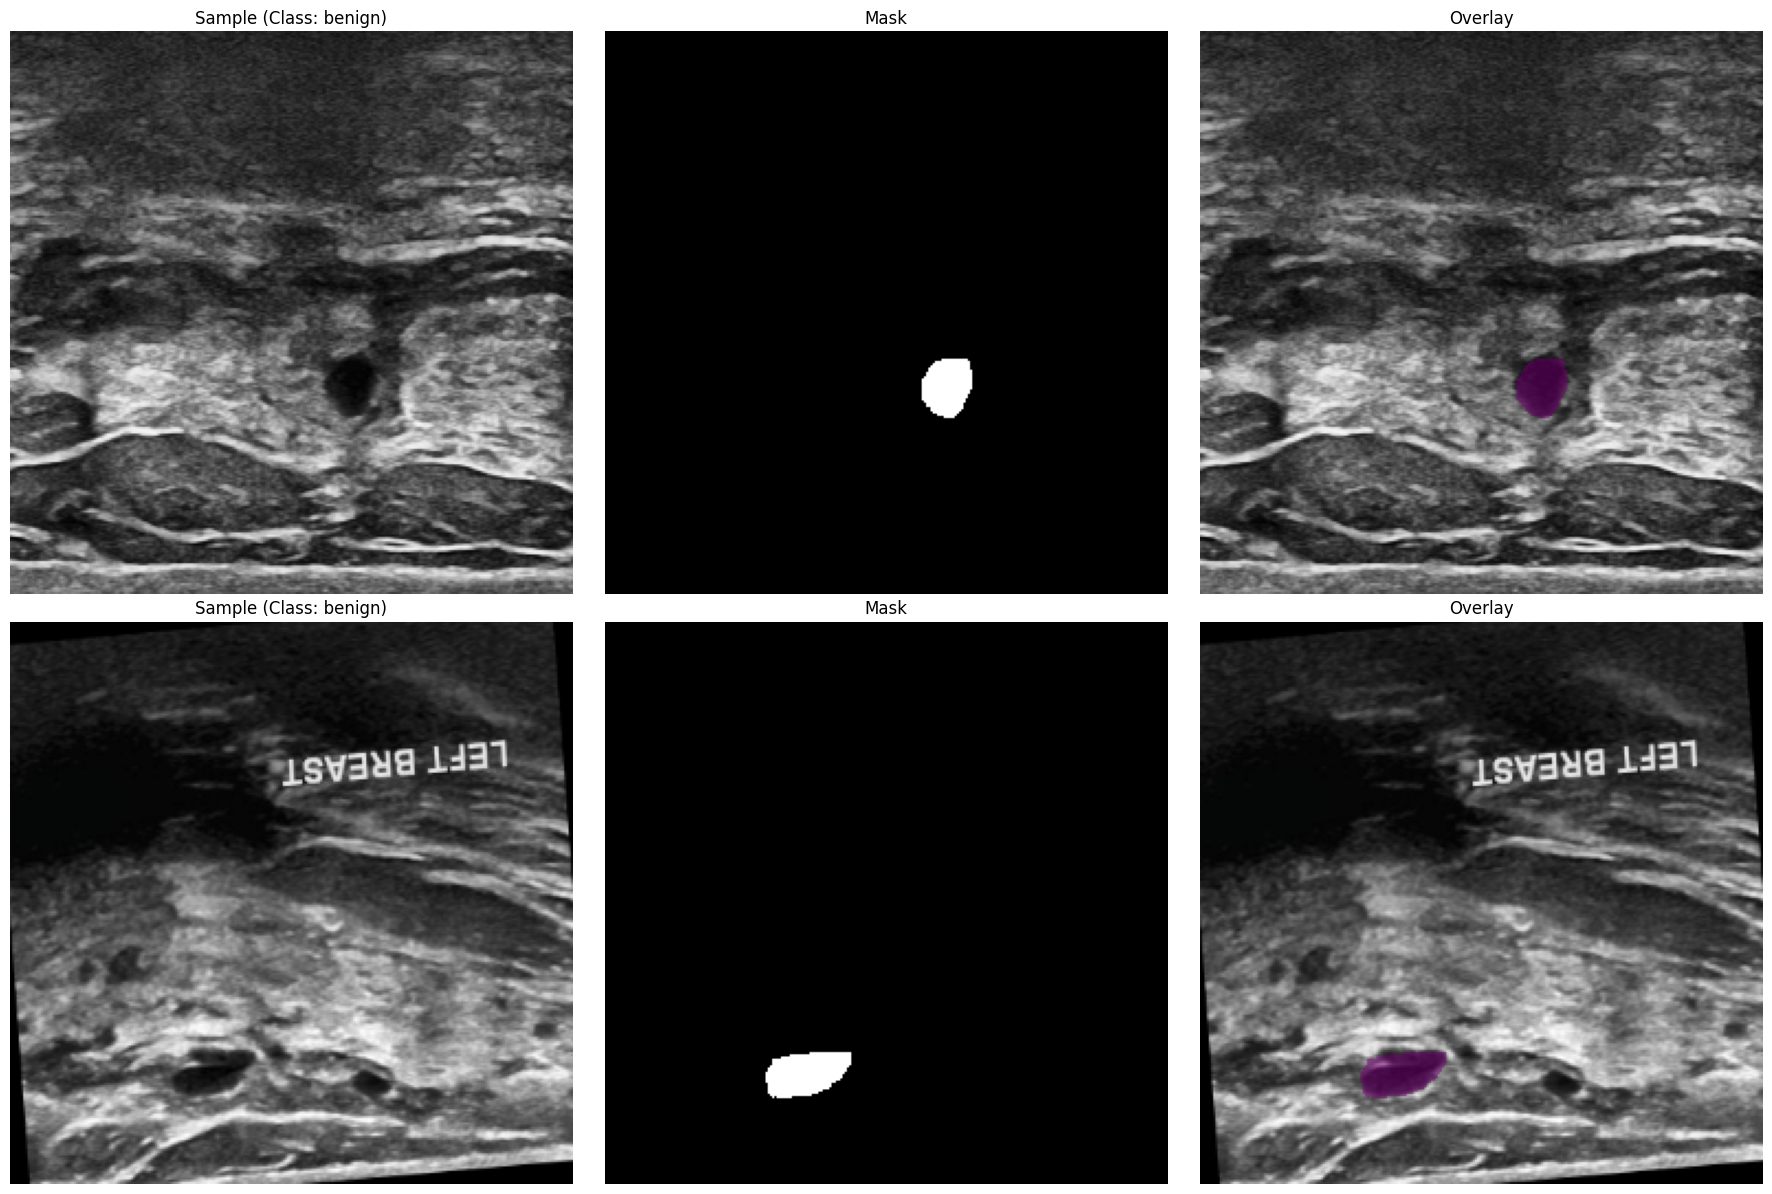

In [45]:
display_samples(train_dset, start_index=95, n_samples=2, mean=mean, std=std)

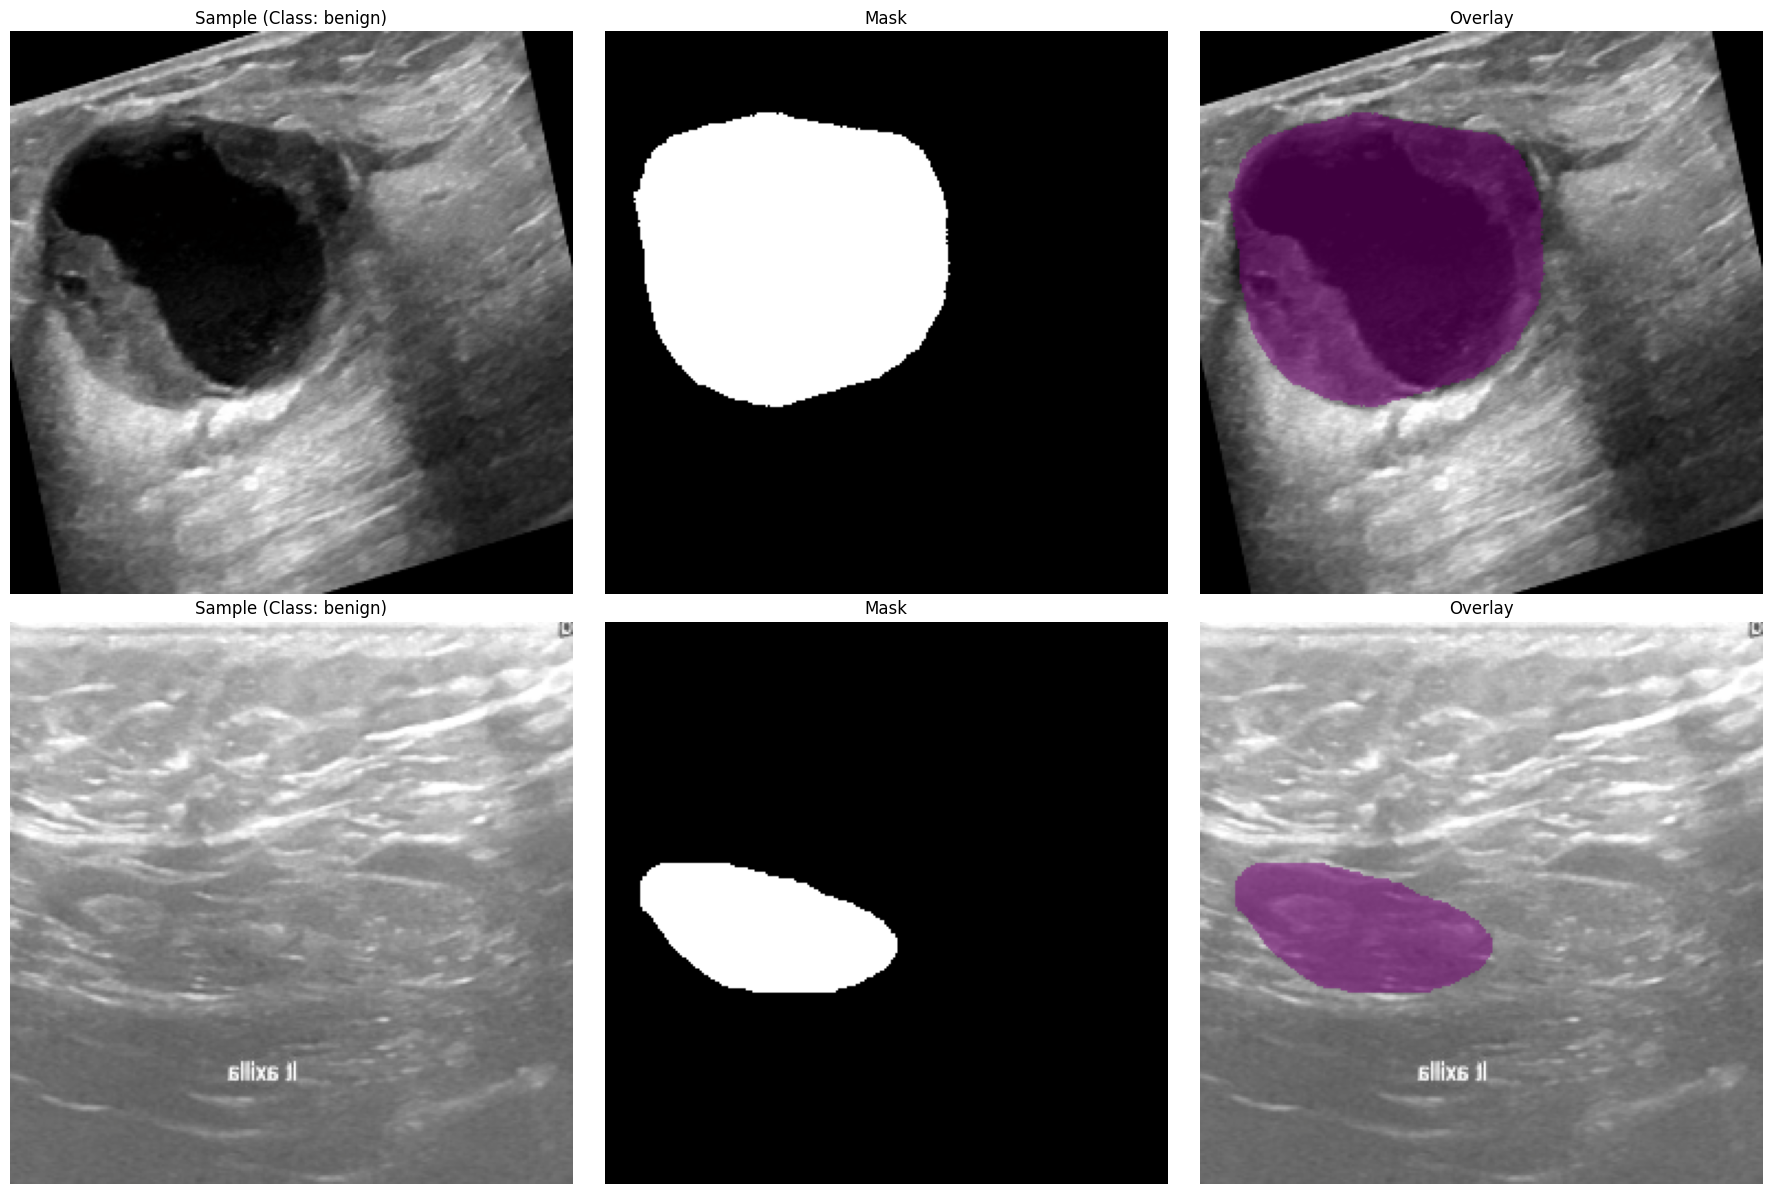

In [46]:
display_samples(train_dset, start_index=347, n_samples=2, mean=mean, std=std)

#### Validation Dataset

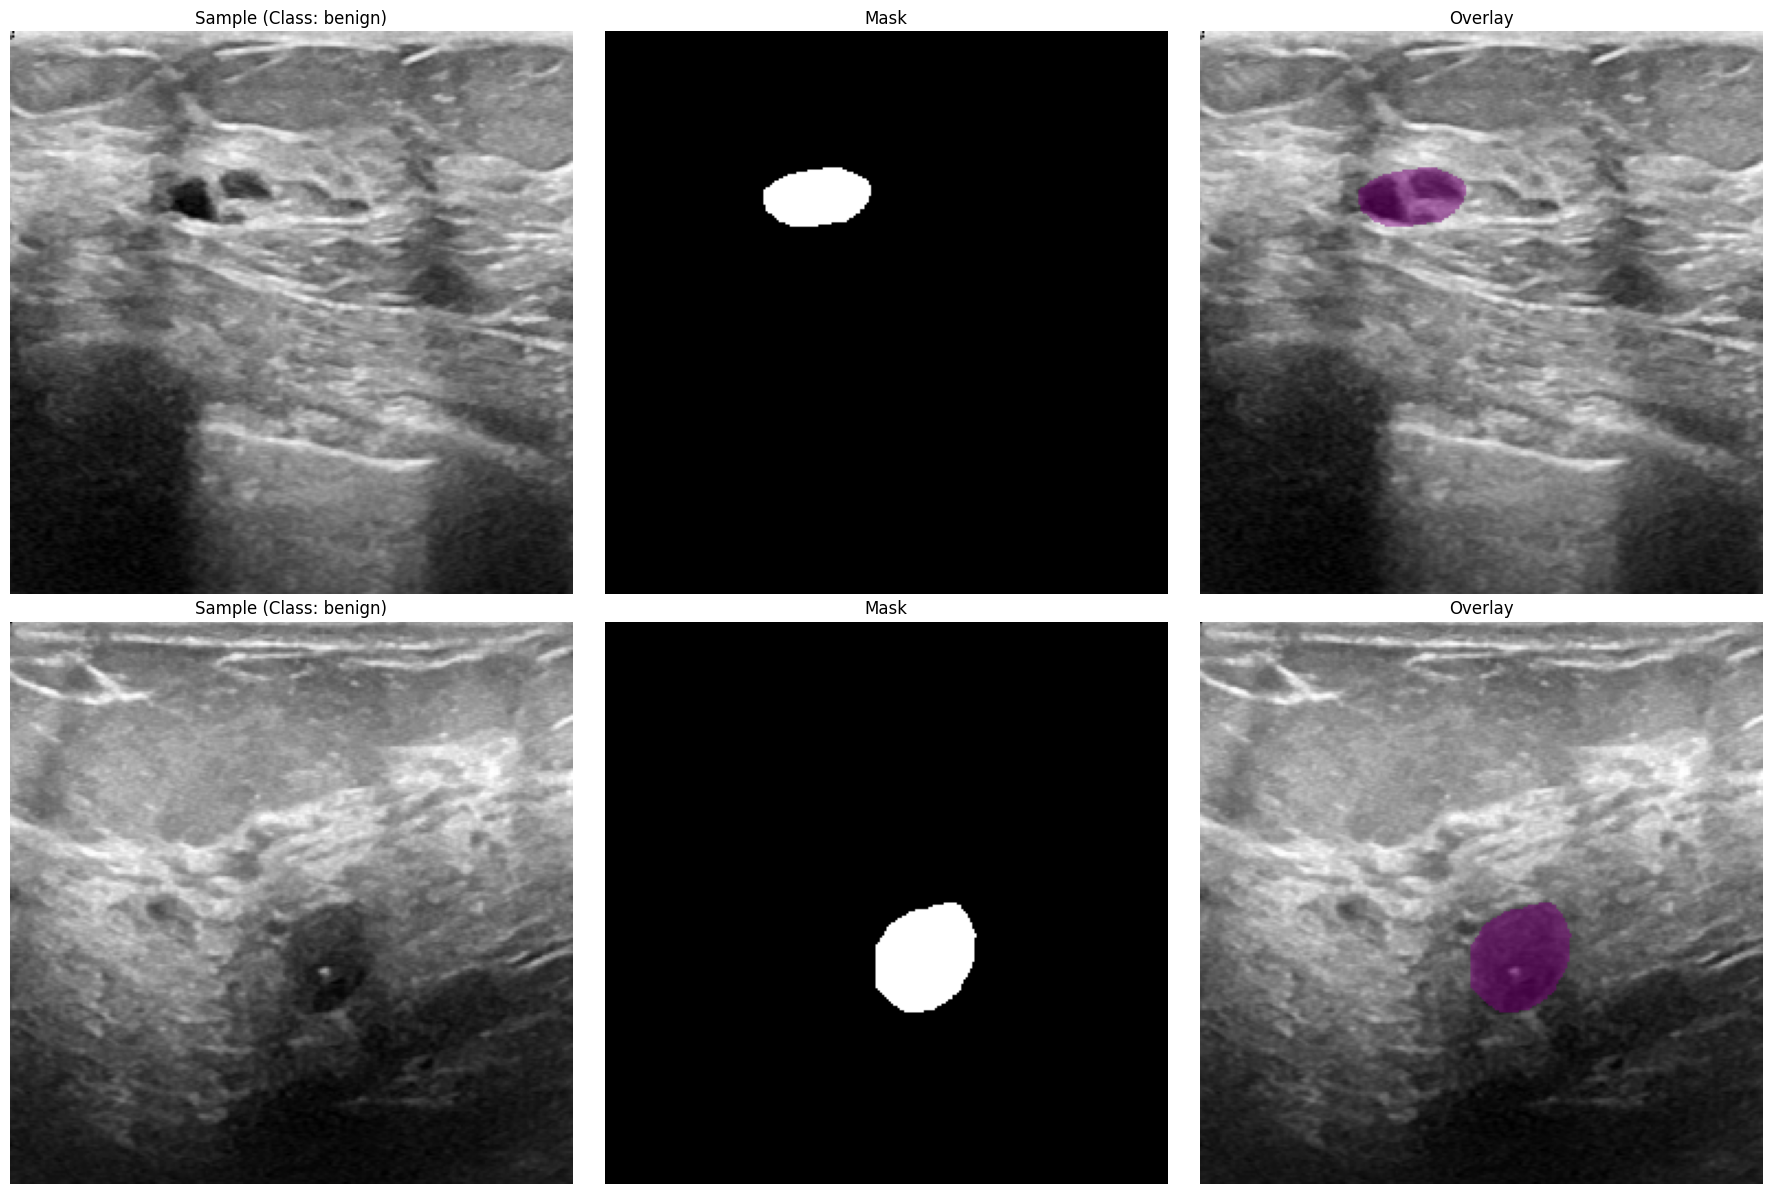

In [47]:
display_samples(val_dset, start_index=0, n_samples=2, mean=mean, std=std)

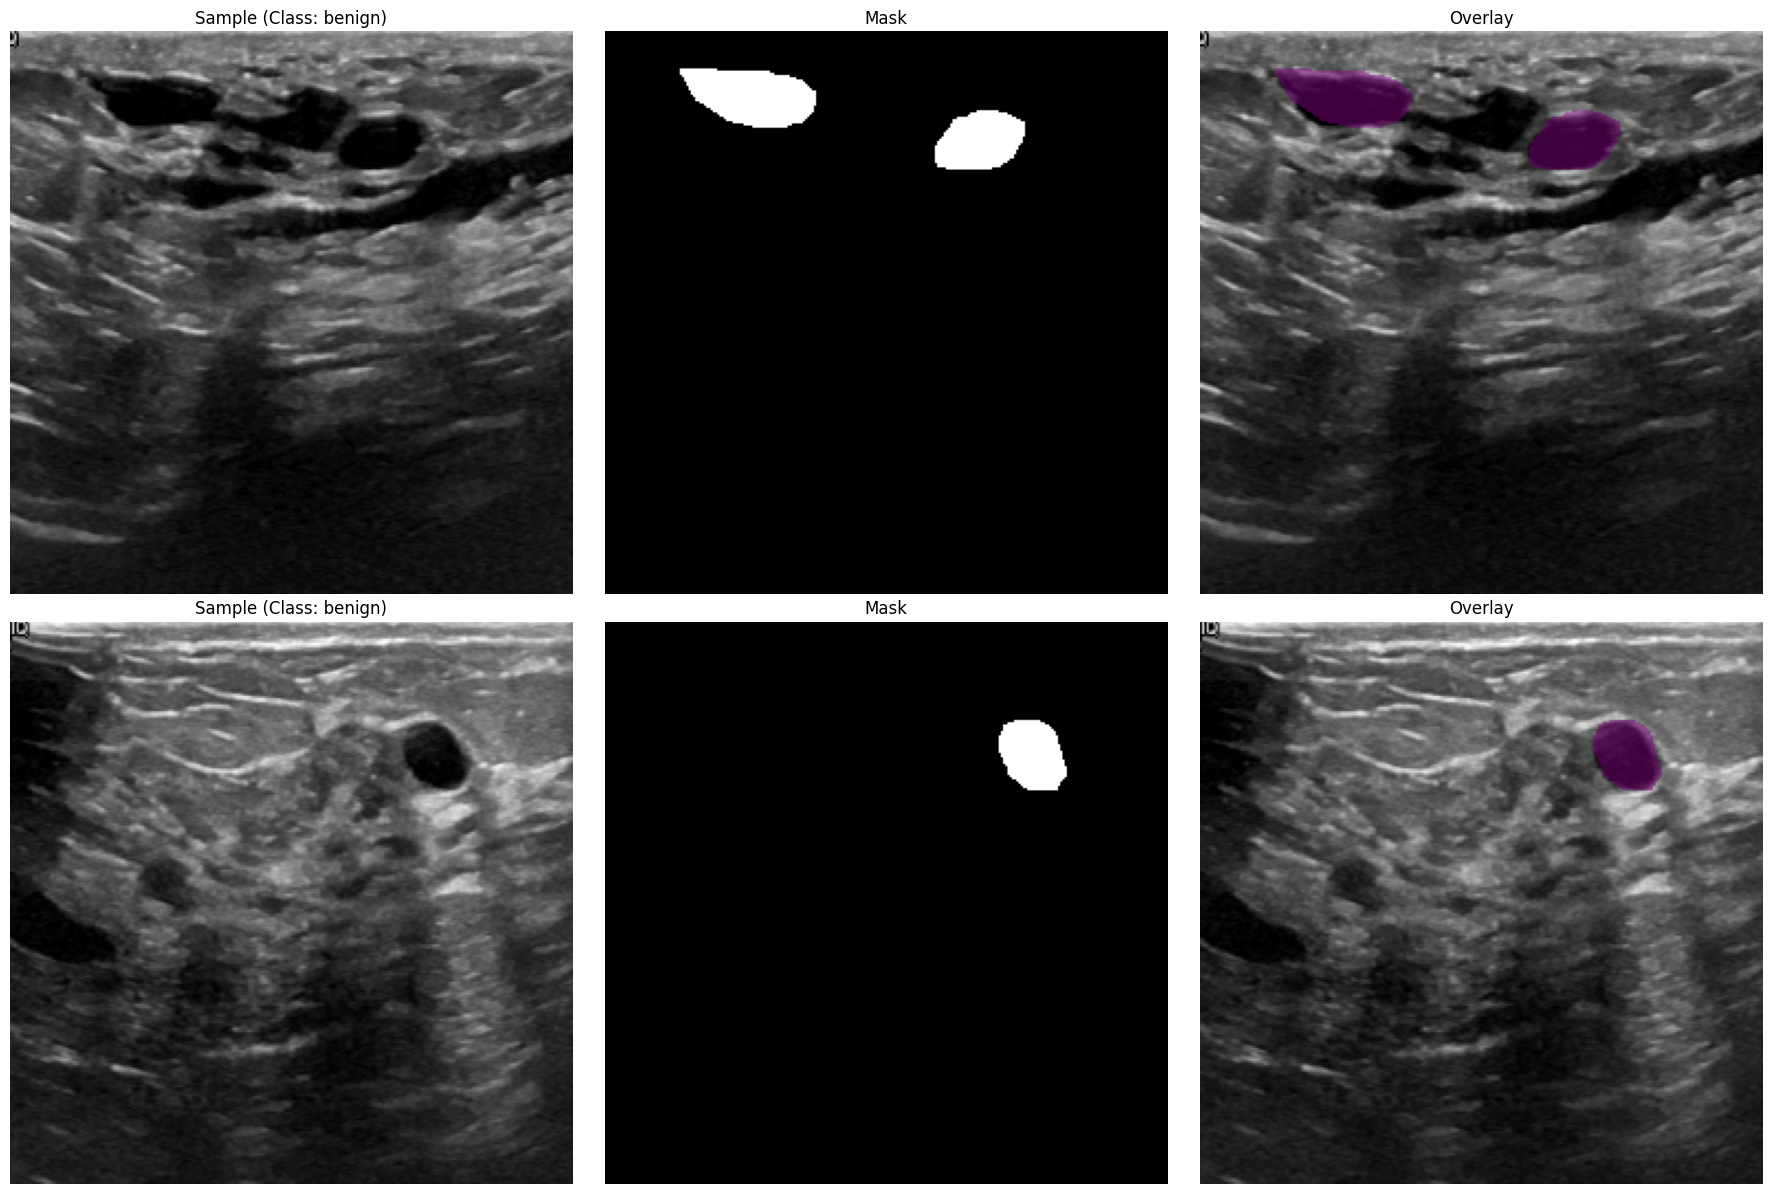

In [48]:
display_samples(val_dset, start_index=80, n_samples=2, mean=mean, std=std)

In [49]:
val_dset.subset.dataset

Dataset SegmentationImageFolder
    Number of datapoints: 547
    Root location: data/complete_set/training_set

### Create data loader

From before we have the ratio of benign to malignant examples in the training set:

In [50]:
print(f"Train Benign to Malignant Ratio: {train_benign_to_malign_ratio:.2f}")

Train Benign to Malignant Ratio: 2.44


FIXME: Come back to addressing class imbalance with the loss function.

Create the train and val datasets, and their respective loaders:

In [51]:
NUM_WORKERS = default_num_workers()
loader_kwargs = dict(batch_size=32, num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_dset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dset, shuffle=False, **loader_kwargs)

Have a look at the loaders:

In [52]:
print('=== Train Loader ===')
print(f"Number of batches in train_loader: {len(train_loader)}")
train_dataset = train_loader.dataset
print(f"Number of samples in train_dataset: {len(train_dataset)}")
print(f"Transforms applied to train_dataset: {train_dataset.transform}")
print(f"train_dataset type: {type(train_dataset)}")

print('\n=== Test Loader ===')
print(f"Number of batches in test_loader: {len(val_loader)}")
val_dataset = val_loader.dataset
print(f"Number of samples in val_dataset: {len(val_dataset)}")
print(f"Transforms applied to val_dataset: {val_dataset.transform}")
print(f"val_dataset type: {type(val_dataset)}")

=== Train Loader ===
Number of batches in train_loader: 14
Number of samples in train_dataset: 437
Transforms applied to train_dataset: Compose([
  RandomBrightnessContrast(p=0.5, brightness_by_max=True, brightness_limit=(-0.4, 0.4), contrast_limit=(-0.4, 0.4), ensure_safe_range=False),
  CLAHE(p=0.2, clip_limit=(1.0, 2.0), tile_grid_size=(8, 8)),
  RandomGamma(p=0.3, gamma_limit=(80.0, 120.0)),
  HorizontalFlip(p=0.5),
  VerticalFlip(p=0.5),
  Rotate(p=0.5, border_mode=0, crop_border=False, fill=0.0, fill_mask=0.0, interpolation=1, limit=(-15.0, 15.0), mask_interpolation=0, rotate_method='largest_box'),
  Resize(p=1.0, area_for_downscale=None, height=256, interpolation=1, mask_interpolation=0, width=256),
  Normalize(p=1.0, max_pixel_value=255.0, mean=(0.33033525943756104, 0.3303266167640686, 0.3302720785140991), normalization='standard', std=(0.20433476567268372, 0.20433692634105682, 0.20429587364196777)),
  ToTensorV2(p=1.0, transpose_mask=False),
], p=1.0, bbox_params=None, keypoin

## Create model and train

In [53]:
# Some training hyperparameters

# TRAIN = False skips training and loads the newest checkpoint in lightning_logs/ instead
# (for example after a kernel restart). Retrain after changing the model, data or settings.
# Running with BC_TRAIN=0 in the environment has the same effect.
TRAIN = os.environ.get("BC_TRAIN", "1") != "0"
EPOCHS = int(os.environ.get("BC_EPOCHS", 50))  # BC_EPOCHS=1 for a quick smoke test
# Always include the background as a class
OUT_CLASSES = len(SegmentationImageFolder.SEGMENTATION_CLASSES)

In [54]:
import pytorch_lightning as pl
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
from torch.optim import lr_scheduler

torch.set_float32_matmul_precision("medium")

class BreastUltrasoundSegmentationModel(pl.LightningModule):
    def __init__(self, arch, encoder_name, encoder_weights, in_channels, out_classes, class_weights=None, **kwargs):
        super().__init__()
        self.model = smp.create_model(
            arch,
            encoder_name=encoder_name,
            encoder_weights=encoder_weights if encoder_weights else None,
            in_channels=in_channels,
            classes=out_classes,
            **kwargs,
        )

        # Preprocessing parameters for image normalization
        #params = smp.encoders.get_preprocessing_params(encoder_name)
        self.number_of_classes = out_classes
        #self.register_buffer("std", torch.tensor(params["std"]).view(1, 3, 1, 1))
        #self.register_buffer("mean", torch.tensor(params["mean"]).view(1, 3, 1, 1))

        # Loss function for multi-class segmentation
        self.dice_loss = smp.losses.DiceLoss(smp.losses.MULTICLASS_MODE, from_logits=True)
        
        # Add weighted CrossEntropyLoss to handle class imbalance
        if class_weights is not None:
            weight_tensor = torch.tensor(class_weights, dtype=torch.float32)
            self.register_buffer("class_weights", weight_tensor)
            self.ce_loss = nn.CrossEntropyLoss(weight=weight_tensor)
        else:
            self.ce_loss = nn.CrossEntropyLoss()

        # Step metrics tracking
        self.training_step_outputs = []
        self.validation_step_outputs = []
        #self.test_step_outputs = []

    def forward(self, image):
        mask = self.model(image)
        return mask

    def shared_step(self, batch, stage):
        image, mask, _ = batch

        # Ensure that image dimensions are correct
        assert image.ndim == 4  # [batch_size, channels, H, W]

        # Ensure the mask is a long (index) tensor
        mask = mask.long()

        # Mask shape
        assert mask.ndim == 3  # [batch_size, H, W]

        # Predict mask logits
        logits_mask = self.forward(image)

        assert (
            logits_mask.shape[1] == self.number_of_classes
        )  # [batch_size, number_of_classes, H, W]

        # Ensure the logits mask is contiguous
        logits_mask = logits_mask.contiguous()

        # Compute combined loss: Dice + weighted CrossEntropy
        dice = self.dice_loss(logits_mask, mask)
        ce = self.ce_loss(logits_mask, mask)
        loss = dice + ce

        # Apply softmax to get probabilities for multi-class segmentation
        prob_mask = logits_mask.softmax(dim=1)

        # Convert probabilities to predicted class labels
        pred_mask = prob_mask.argmax(dim=1)

        # Compute true positives, false positives, false negatives, and true negatives
        tp, fp, fn, tn = smp.metrics.get_stats(
            pred_mask, mask, mode="multiclass", num_classes=self.number_of_classes
        )

        return {
            "loss": loss,
            "tp": tp,
            "fp": fp,
            "fn": fn,
            "tn": tn,
        }

    def shared_epoch_end(self, outputs, stage):
        # Aggregate step metrics
        tp = torch.cat([x["tp"] for x in outputs])
        fp = torch.cat([x["fp"] for x in outputs])
        fn = torch.cat([x["fn"] for x in outputs])
        tn = torch.cat([x["tn"] for x in outputs])

        # Per-image IoU and dataset IoU calculations
        per_image_iou = smp.metrics.iou_score(
            tp, fp, fn, tn, reduction="micro-imagewise"
        )
        dataset_iou = smp.metrics.iou_score(tp, fp, fn, tn, reduction="micro")

        metrics = {
            f"{stage}_per_image_iou": per_image_iou,
            f"{stage}_dataset_iou": dataset_iou,
        }

        self.log_dict(metrics, prog_bar=True)

    def training_step(self, batch, batch_idx):
        train_loss_info = self.shared_step(batch, "train")
        self.training_step_outputs.append(train_loss_info)
        return train_loss_info

    def on_train_epoch_end(self):
        self.shared_epoch_end(self.training_step_outputs, "train")
        self.training_step_outputs.clear()

    def validation_step(self, batch, batch_idx):
        valid_loss_info = self.shared_step(batch, "valid")
        self.validation_step_outputs.append(valid_loss_info)
        return valid_loss_info

    def on_validation_epoch_end(self):
        self.shared_epoch_end(self.validation_step_outputs, "valid")
        self.validation_step_outputs.clear()

    def test_step(self, batch, batch_idx):
        test_loss_info = self.shared_step(batch, "test")
        self.test_step_outputs.append(test_loss_info)
        return test_loss_info

    def on_test_epoch_end(self):
        self.shared_epoch_end(self.test_step_outputs, "test")
        self.test_step_outputs.clear()

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=2e-4)
        # Decay over the whole run (every training step), from 2e-4 down to 1e-5.
        total_steps = self.trainer.estimated_stepping_batches
        scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps, eta_min=1e-5)
        return {
            "optimizer": optimizer,
            "lr_scheduler": {
                "scheduler": scheduler,
                "interval": "step",
                "frequency": 1,
            },
        }


In [55]:
model = BreastUltrasoundSegmentationModel(
    arch="UNET", 
    encoder_name="resnet34", 
    encoder_weights="imagenet", 
    in_channels=3, 
    out_classes=OUT_CLASSES,
    class_weights=class_weights
)


### Training

In [56]:
trainer = pl.Trainer(max_epochs=EPOCHS, log_every_n_steps=1, accelerator="auto")  # CUDA on Linux, MPS on Apple Silicon

if TRAIN:
    trainer.fit(
        model,
        train_dataloaders=train_loader,
        val_dataloaders=val_loader,
    )
else:
    # Reuse the newest checkpoint from an earlier run (Lightning saves one at the end of training).
    ckpts = sorted(Path("lightning_logs").glob("version_*/checkpoints/*.ckpt"), key=lambda p: p.stat().st_mtime)
    if not ckpts:
        raise FileNotFoundError("TRAIN is False, but there is no checkpoint under lightning_logs/: set TRAIN = True.")
    checkpoint = torch.load(ckpts[-1], map_location="cpu", weights_only=False)  # our own file, so trusted
    model.load_state_dict(checkpoint["state_dict"])
    print(f"TRAIN is False: loaded trained weights from {ckpts[-1]}")

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
Loading `train_dataloader` to estimate number of stepping batches.

  | Name      | Type             | Params | Mode  | FLOPs
---------------------------------------------------------------
0 | model     | Unet             | 24.4 M | train | 0    
1 | dice_loss | DiceLoss         | 0      | train | 0    
2 | ce_loss   | CrossEntropyLoss | 0      | train | 0    
---------------------------------------------------------------
24.4 M    Trainable params
0         Non-trainable params


Epoch 49: 100%|██████████| 14/14 [00:08<00:00,  1.73it/s, v_num=2, valid_per_image_iou=0.946, valid_dataset_iou=0.941, train_per_image_iou=0.962, train_dataset_iou=0.960]

`Trainer.fit` stopped: `max_epochs=50` reached.


Epoch 49: 100%|██████████| 14/14 [00:08<00:00,  1.67it/s, v_num=2, valid_per_image_iou=0.946, valid_dataset_iou=0.941, train_per_image_iou=0.962, train_dataset_iou=0.960]


### Validation

In [57]:
# run validation dataset
valid_metrics = trainer.validate(model, dataloaders=val_loader, verbose=False)
print(valid_metrics)

Validation DataLoader 0: 100%|██████████| 4/4 [00:00<00:00,  4.01it/s]
[{'valid_per_image_iou': 0.9456162452697754, 'valid_dataset_iou': 0.9407274127006531}]


### Lesion-level metrics

The IoU printed above is averaged over **all three classes, including background**. Background is most of every image and easy to get right, so that number looks high even when lesions are poorly outlined: a model that predicted no lesions at all would still score well on it. The measures below look only at the lesion.

**Lesion overlap (IoU, intersection over union).** Take the pixels the model marked as lesion and the pixels the expert marked as lesion. IoU is the area they share divided by the area covered by either:

$$\text{IoU} = \frac{|\text{predicted} \cap \text{true}|}{|\text{predicted} \cup \text{true}|}$$

1 means the outlines match exactly and 0 means no overlap. Missing part of the lesion and marking extra tissue both lower it. An IoU of 0.5 is a common threshold for "found the lesion".

**Lesion Dice.** The shared area counted against the *sizes* of the two outlines:

$$\text{Dice} = \frac{2\,|\text{predicted} \cap \text{true}|}{|\text{predicted}| + |\text{true}|}$$

It is the pixel-level F1 score (the balance of precision and recall), and the most widely reported score for medical image segmentation. It always comes out higher than IoU for the same prediction, since Dice = 2·IoU / (1 + IoU): an IoU of 0.5 is a Dice of 0.67, and an IoU of 0.75 is a Dice of 0.86.

Both are computed per image on the lesion only (benign and malignant pixels together, ignoring which class), then averaged.

**Image-level accuracy.** Whether the model's call for the whole image, the majority class among its lesion pixels, matches the expert's label. This measures classification, separately from how well the outline fits.

**Post-processing.** The raw prediction can contain stray extra regions, and can label part of one lesion benign and part malignant. `postprocess` keeps only the largest connected lesion region and gives all of it the majority class. Both versions are scored below.


In [58]:
from scipy import ndimage
import pandas as pd

CLASS_NAMES = SegmentationImageFolder.SEGMENTATION_CLASSES  # background, benign, malignant


def lesion_call(pred):
    """The class the model gives the image: the majority class among its lesion pixels (0 if none)."""
    lesion = pred[pred > 0]
    if lesion.numel() == 0:
        return 0
    return int(torch.bincount(lesion, minlength=3)[1:].argmax()) + 1


def postprocess(pred):
    """Keep only the largest connected lesion region, and give all of it its majority class."""
    regions, n = ndimage.label((pred > 0).cpu().numpy())
    if n == 0:
        return pred.clone()
    sizes = ndimage.sum(np.ones_like(regions), regions, index=range(1, n + 1))
    keep = torch.from_numpy(regions == int(np.argmax(sizes)) + 1)
    out = torch.zeros_like(pred)
    out[keep] = lesion_call(torch.where(keep, pred, torch.zeros_like(pred)))
    return out


def lesion_overlap(pred, true):
    """IoU and Dice of the lesion (benign + malignant together) against the expert's outline."""
    p, t = pred > 0, true > 0
    shared = (p & t).sum().item()
    either, sizes = (p | t).sum().item(), p.sum().item() + t.sum().item()
    return (shared / either if either else 1.0), (2 * shared / sizes if sizes else 1.0)


# Predict every validation image once
model.eval()
device = next(model.parameters()).device
val_true, val_pred, val_class = [], [], []
viz_images = None  # the first batch of images, kept for the visualisation below
with torch.inference_mode():
    for images, masks, class_ids in val_loader:
        if viz_images is None:
            viz_images = images
        val_pred += list(model(images.to(device)).argmax(dim=1).cpu())
        val_true += list(masks.long())
        val_class += [int(c) + 1 for c in class_ids]  # 1 = benign, 2 = malignant


def score(preds):
    rows = []
    for pred, true, cls in zip(preds, val_true, val_class):
        iou, dice = lesion_overlap(pred, true)
        lesion = pred[pred > 0]
        rows.append(dict(cls=cls, call=lesion_call(pred), iou=iou, dice=dice,
                         split=bool((lesion == 1).any() and (lesion == 2).any())))
    df = pd.DataFrame(rows)
    correct = df.call == df.cls
    return {
        "Lesion IoU (mean)": df.iou.mean(),
        "Lesion IoU (median)": df.iou.median(),
        "Lesion Dice (mean)": df.dice.mean(),
        "Images with lesion IoU < 0.5": int((df.iou < 0.5).sum()),
        "Image-level accuracy": correct.mean(),
        "  benign images correct": correct[df.cls == 1].mean(),
        "  malignant images correct": correct[df.cls == 2].mean(),
        "Lesions split benign/malignant": int(df.split.sum()),
        "Images with no lesion predicted": int((df.call == 0).sum()),
    }


val_post = [postprocess(p) for p in val_pred]
lesion_metrics = pd.DataFrame({"Raw prediction": score(val_pred), "Post-processed": score(val_post)})
print(f"{len(val_true)} validation images: {val_class.count(1)} benign, {val_class.count(2)} malignant")
lesion_metrics.round(3)


110 validation images: 77 benign, 33 malignant


,Raw prediction,Post-processed
Lesion IoU (mean),0.746,0.746
Lesion IoU (median),0.818,0.814
Lesion Dice (mean),0.830,0.829
Images with lesion IoU < 0.5,11.000,11.000
Image-level accuracy,0.909,0.909
benign images correct,0.948,0.948
malignant images correct,0.818,0.818
Lesions split benign/malignant,2.000,0.000
Images with no lesion predicted,2.000,2.000


### Validation visualization

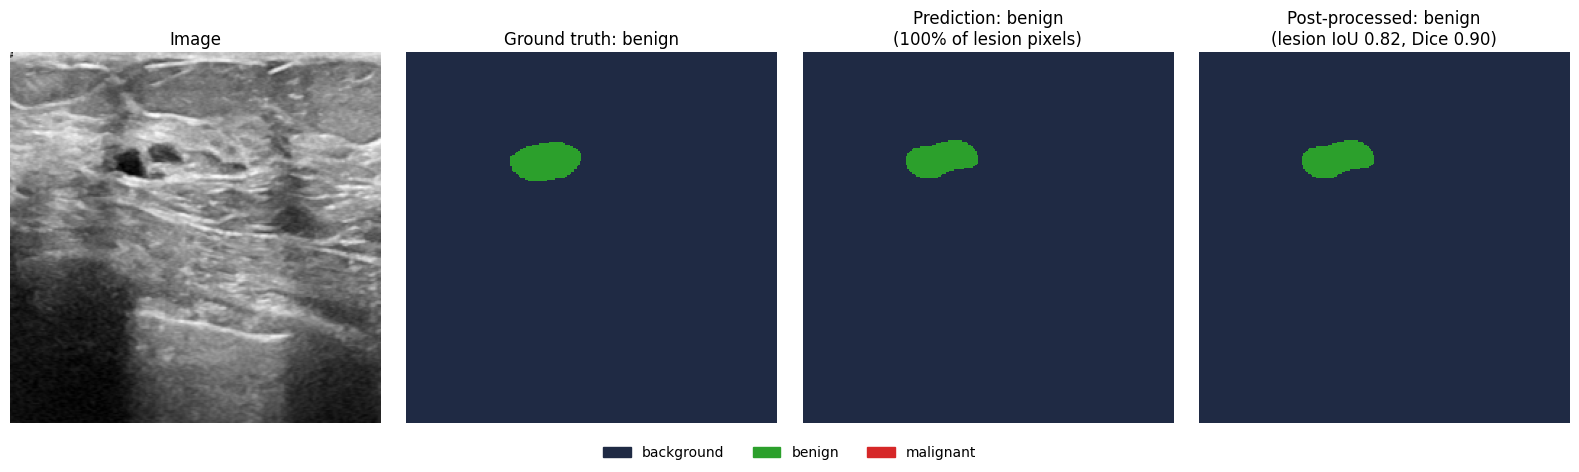

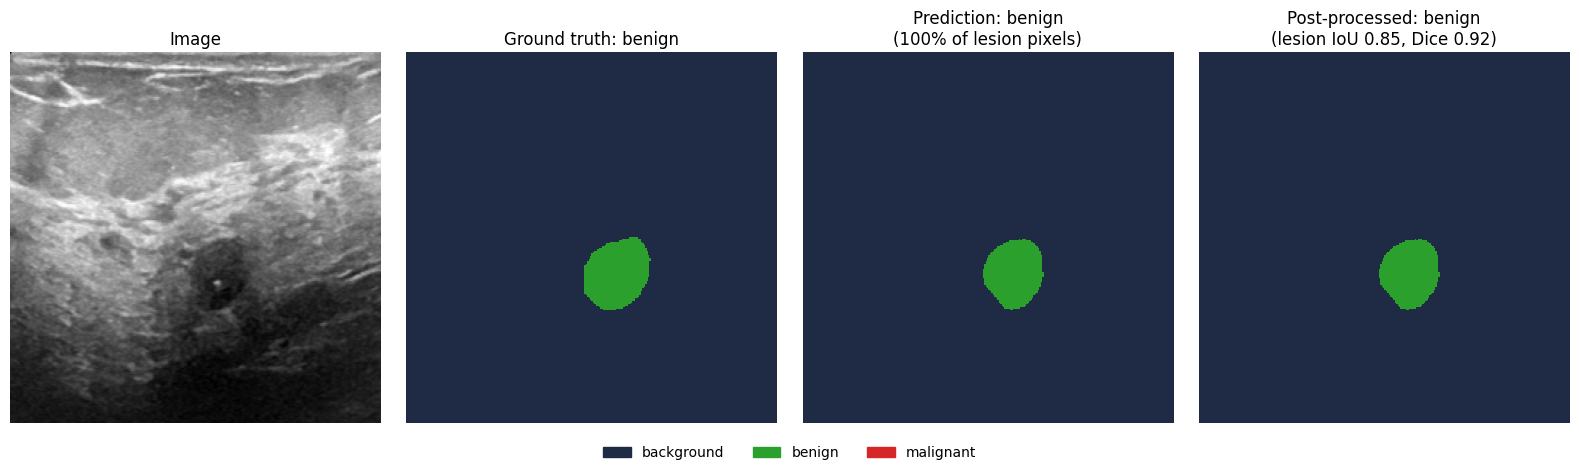

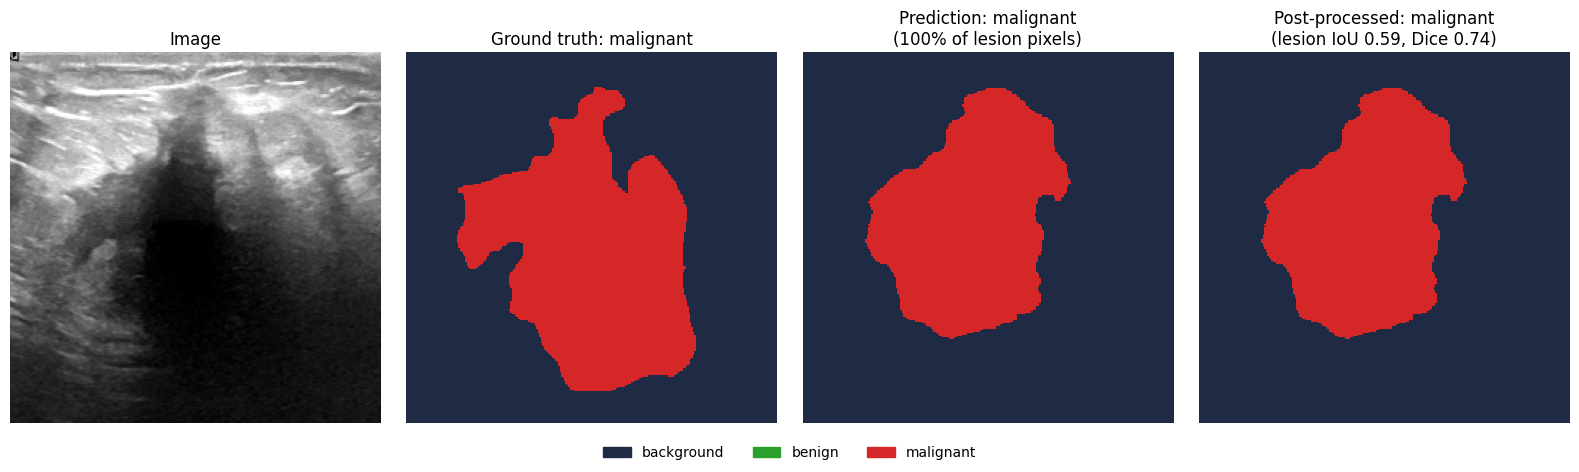

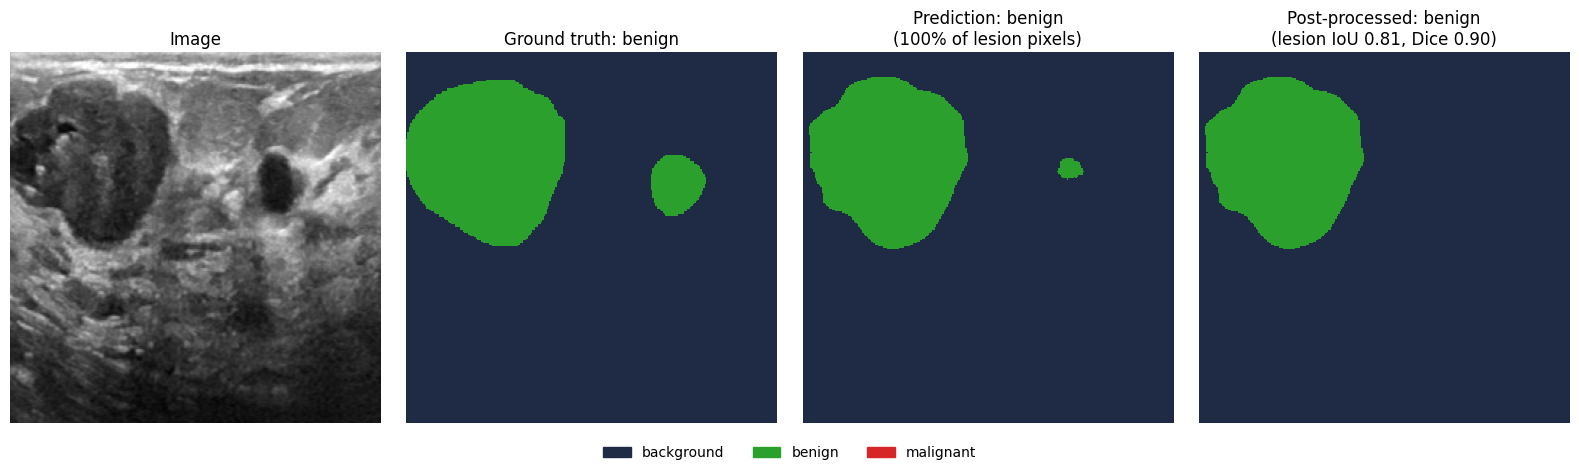

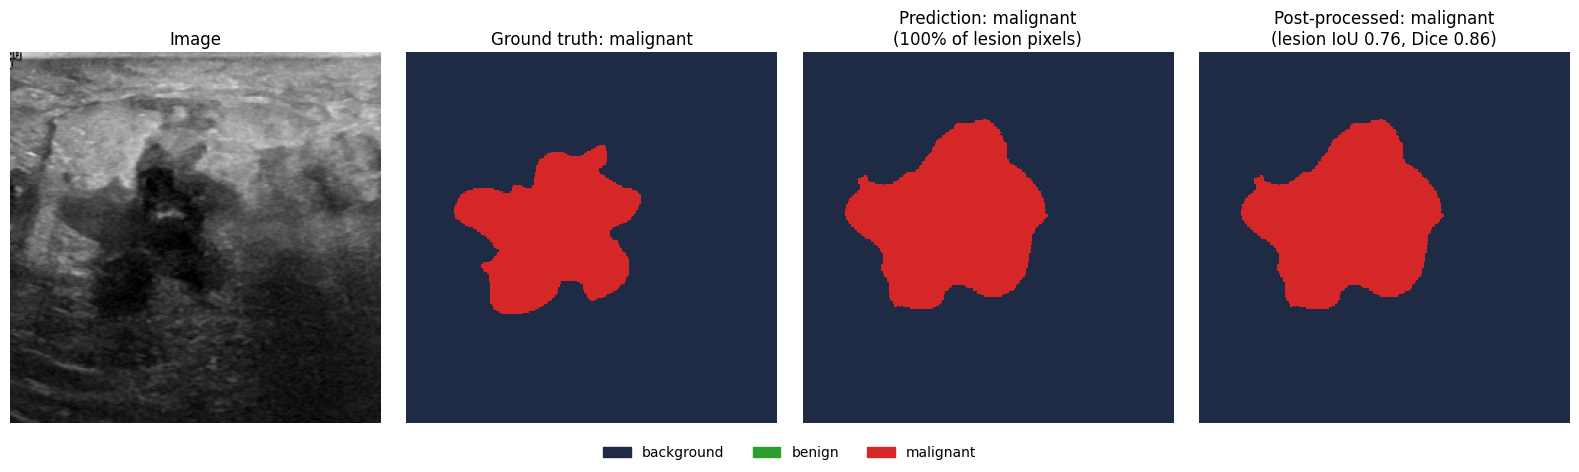

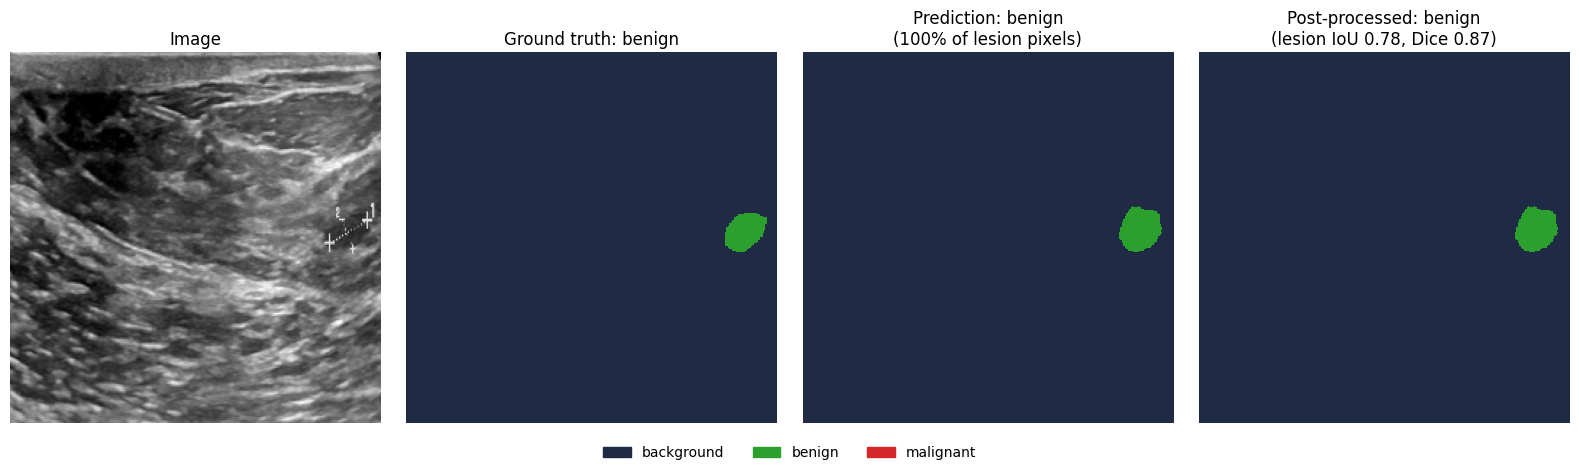

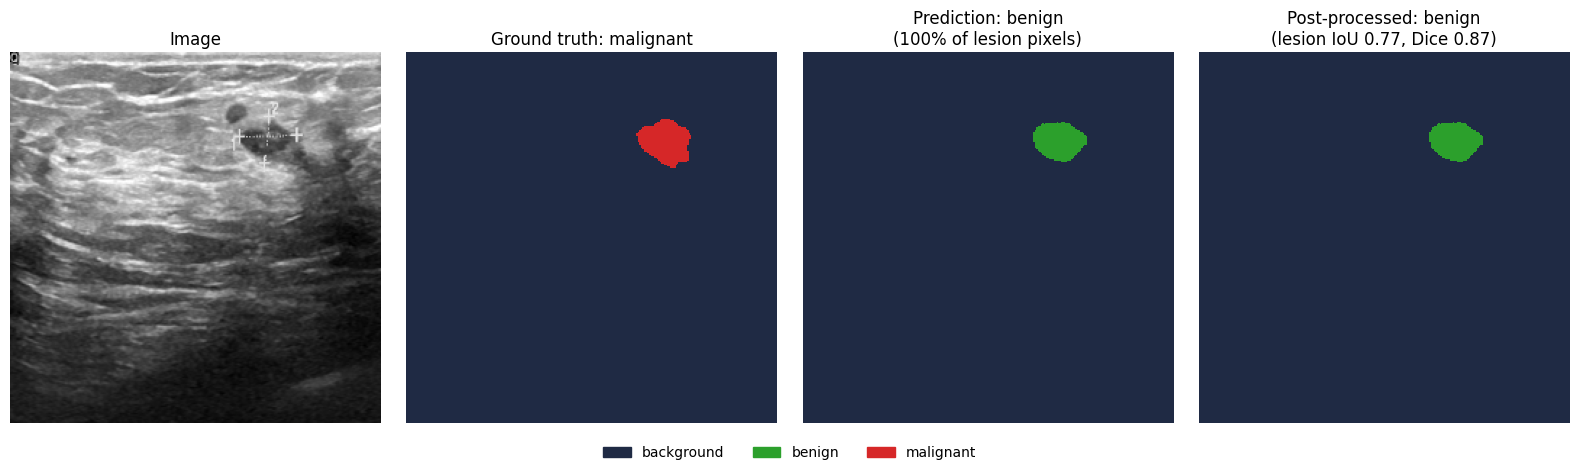

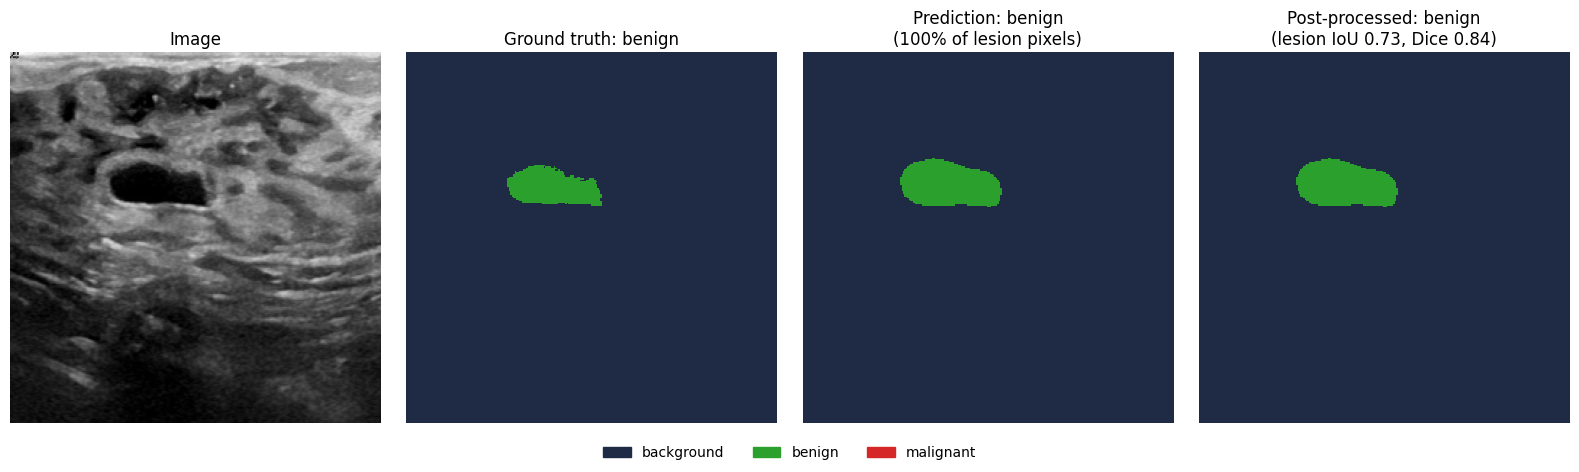

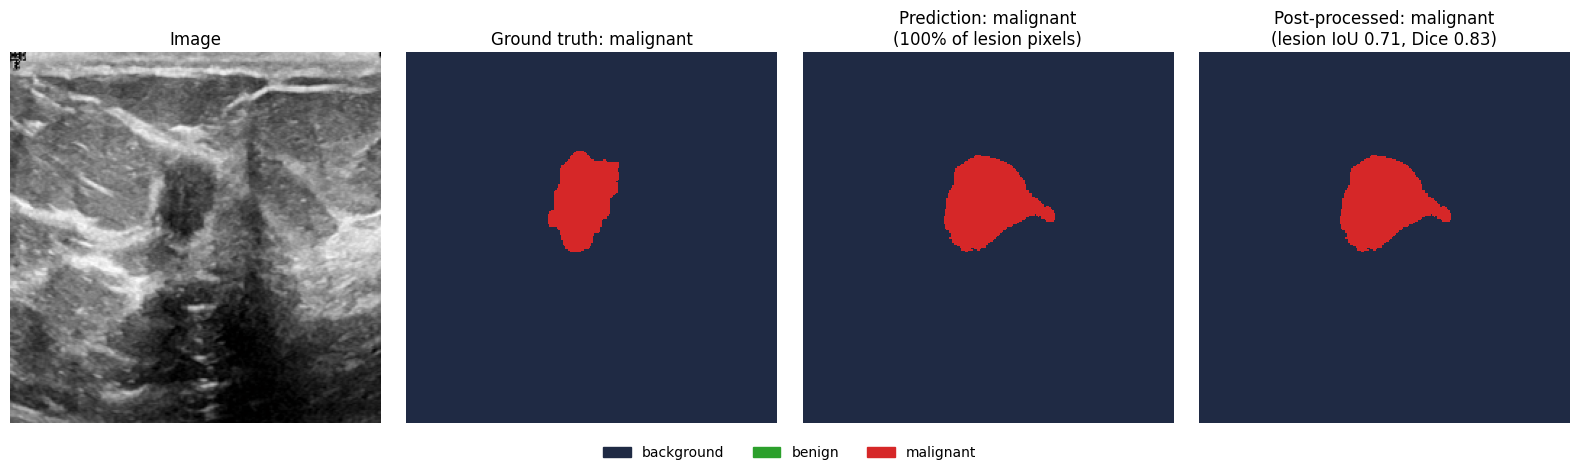

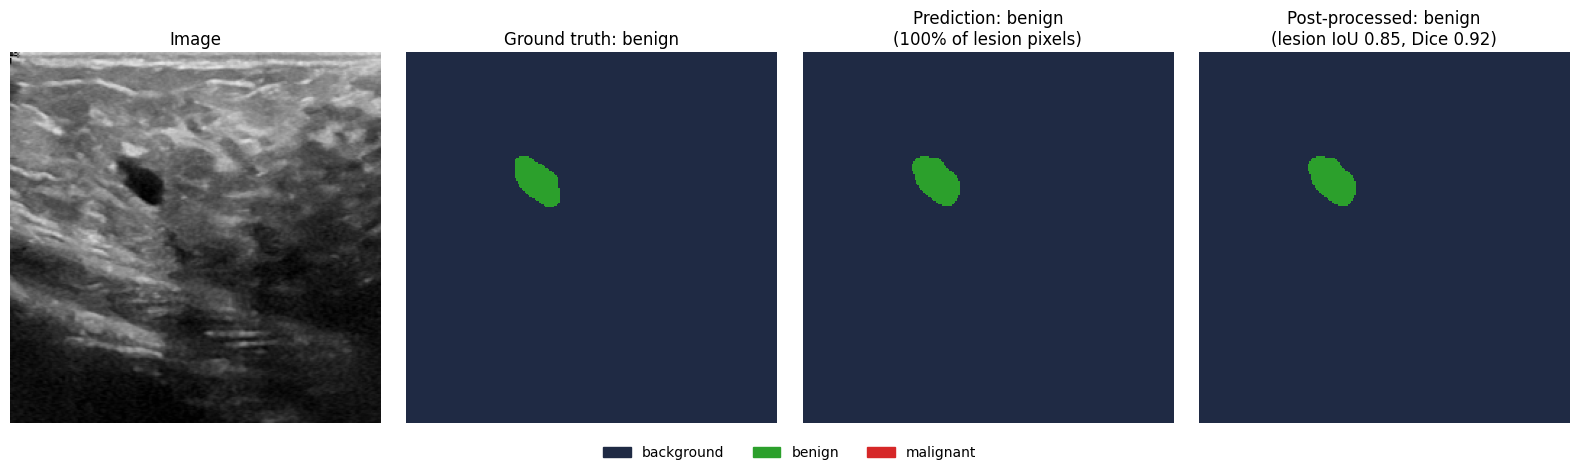

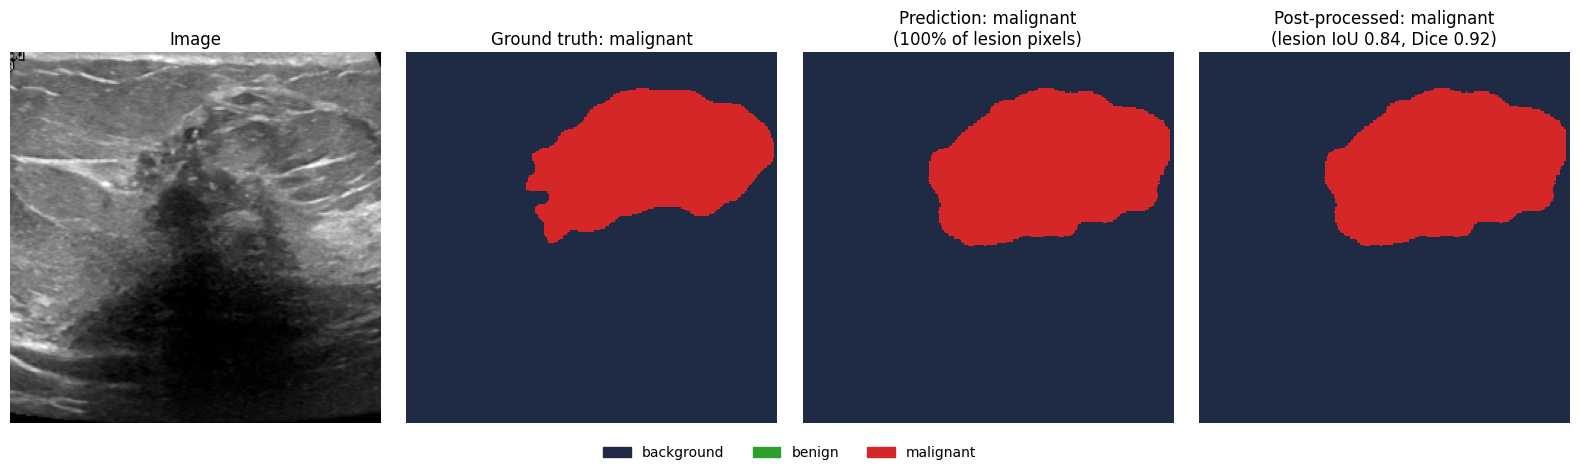

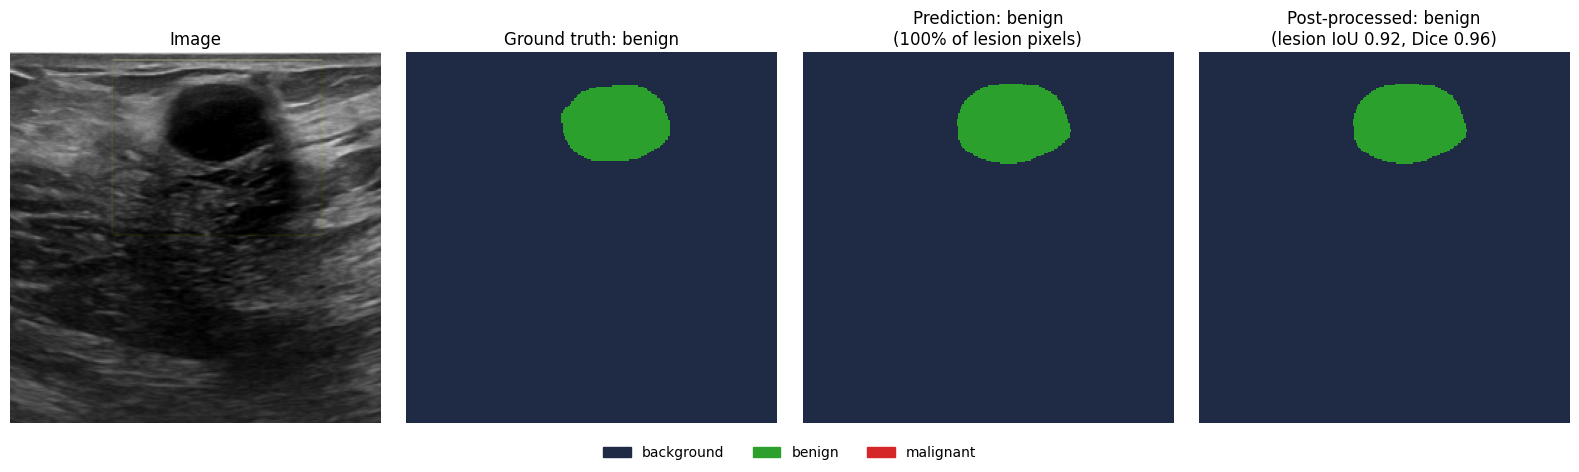

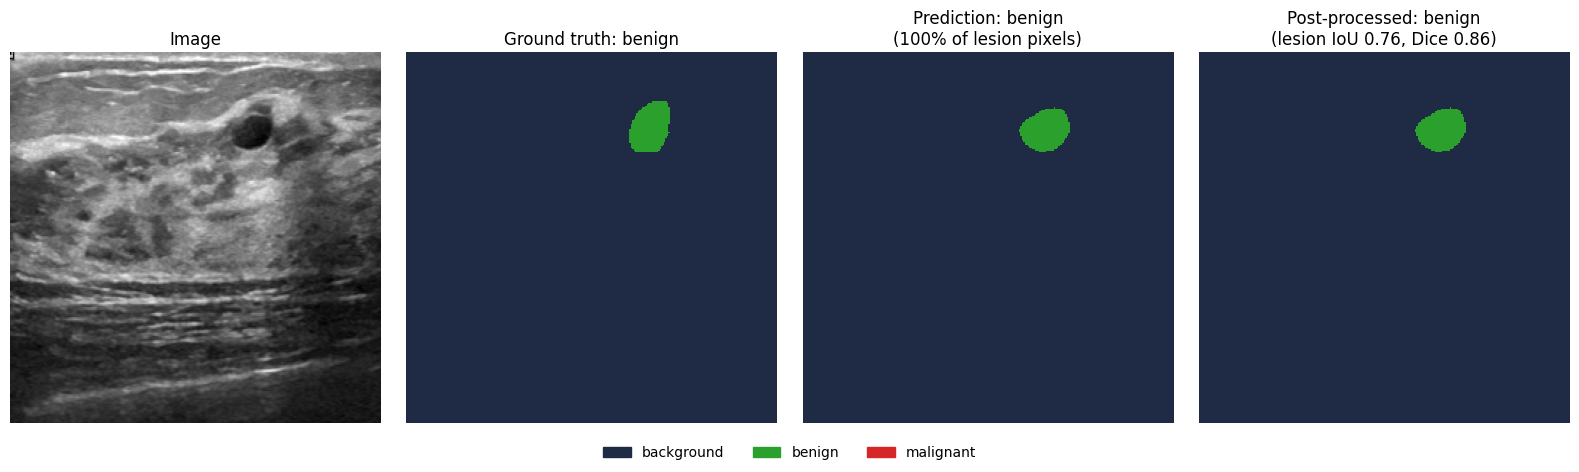

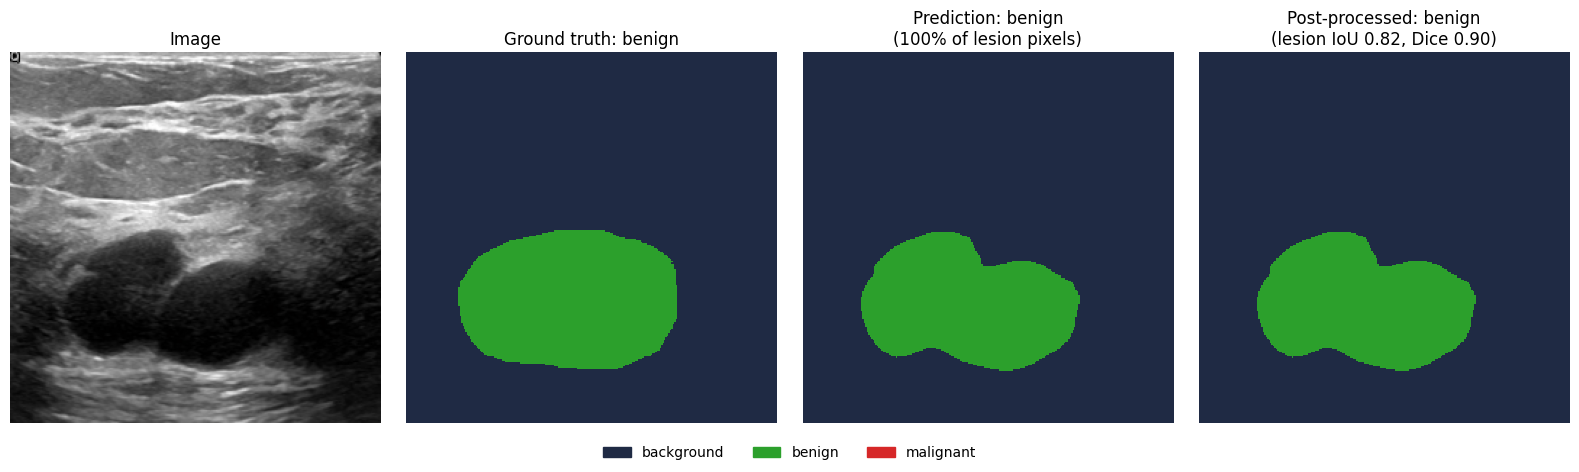

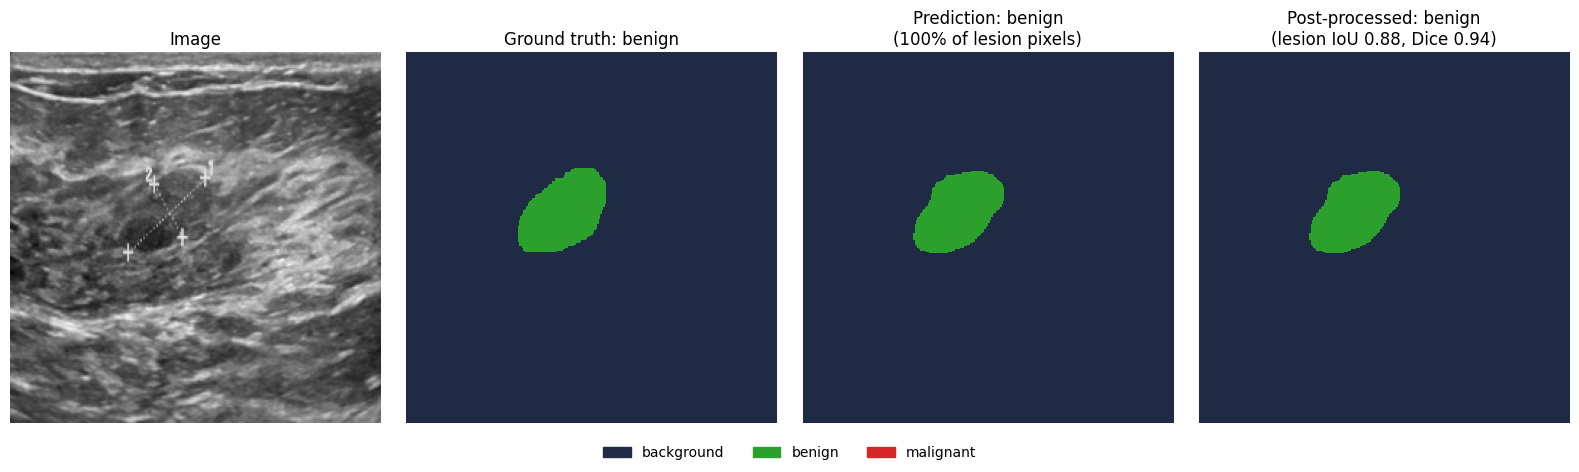

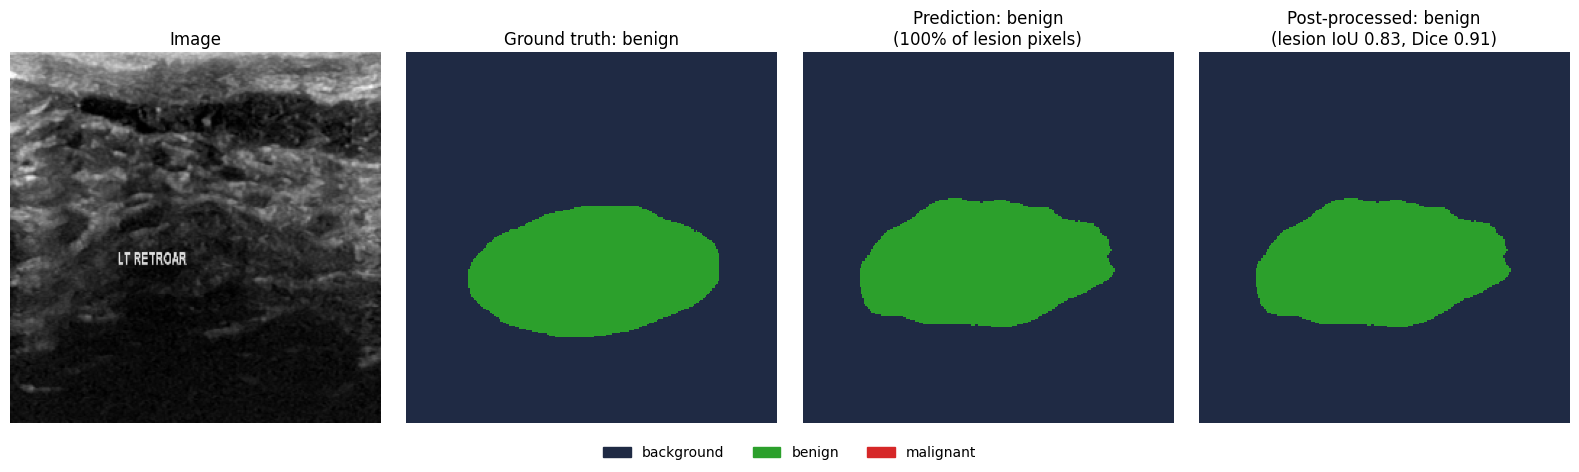

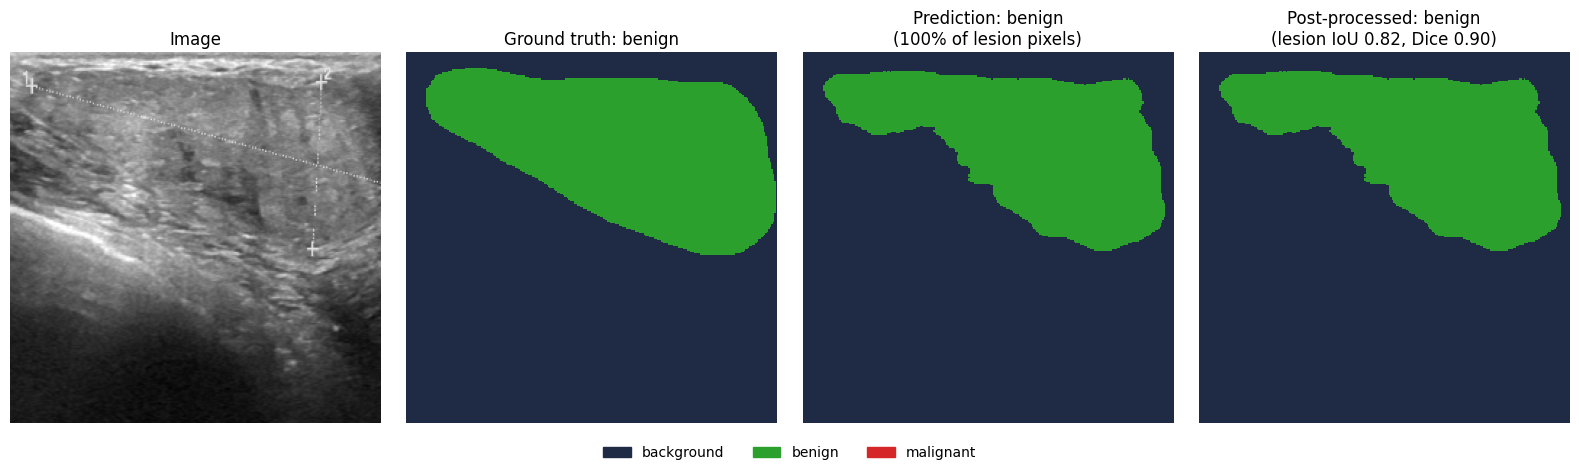

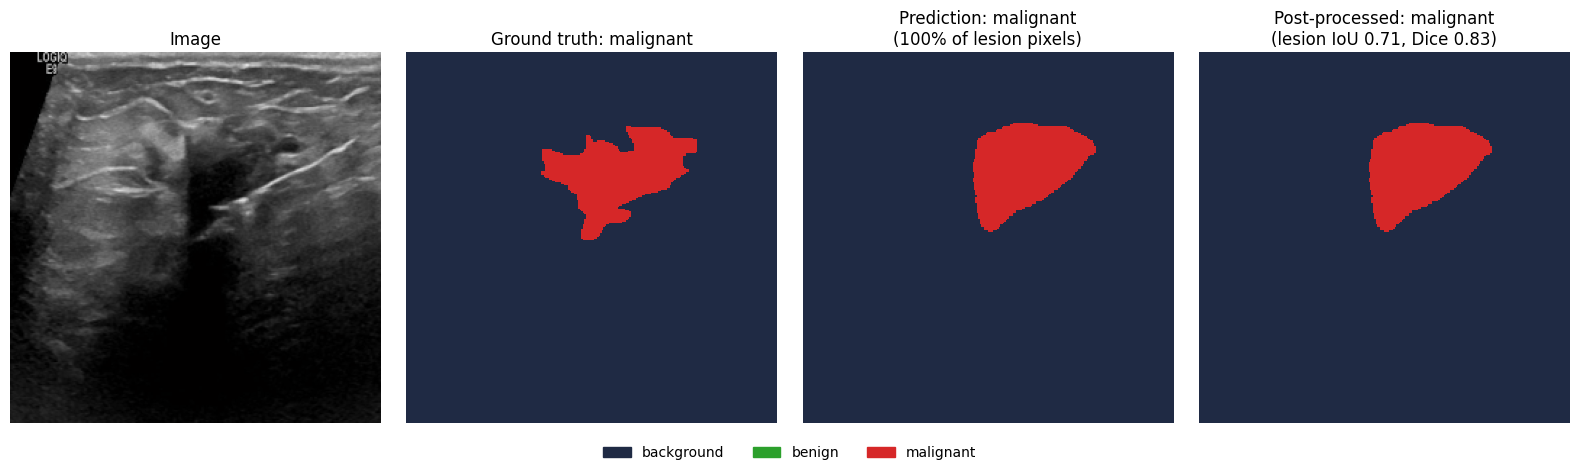

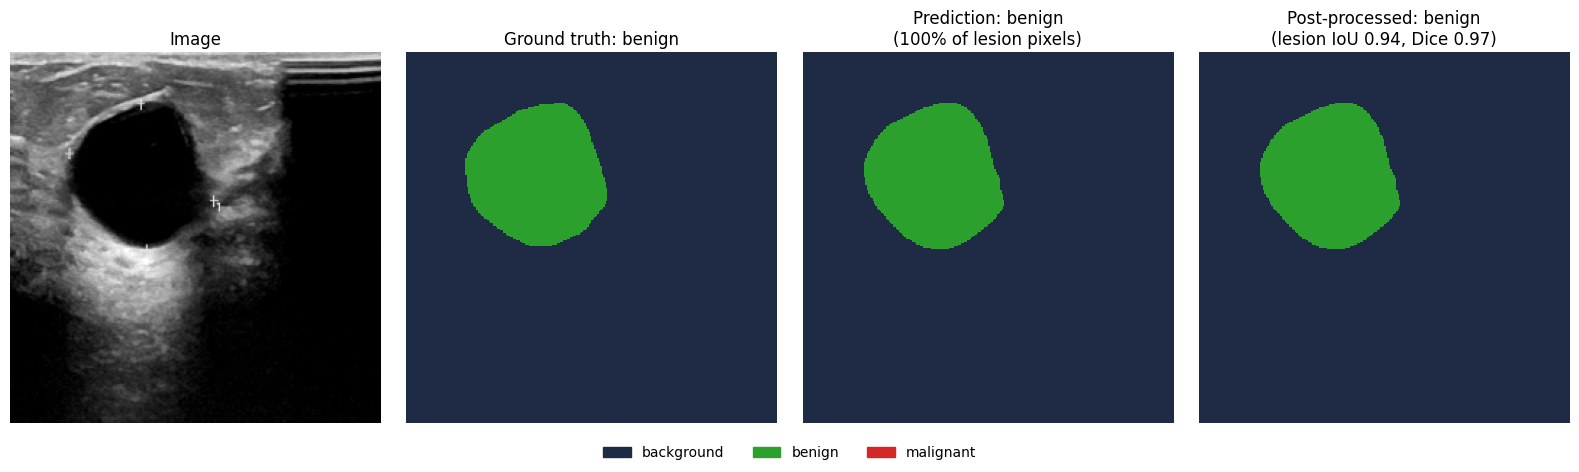

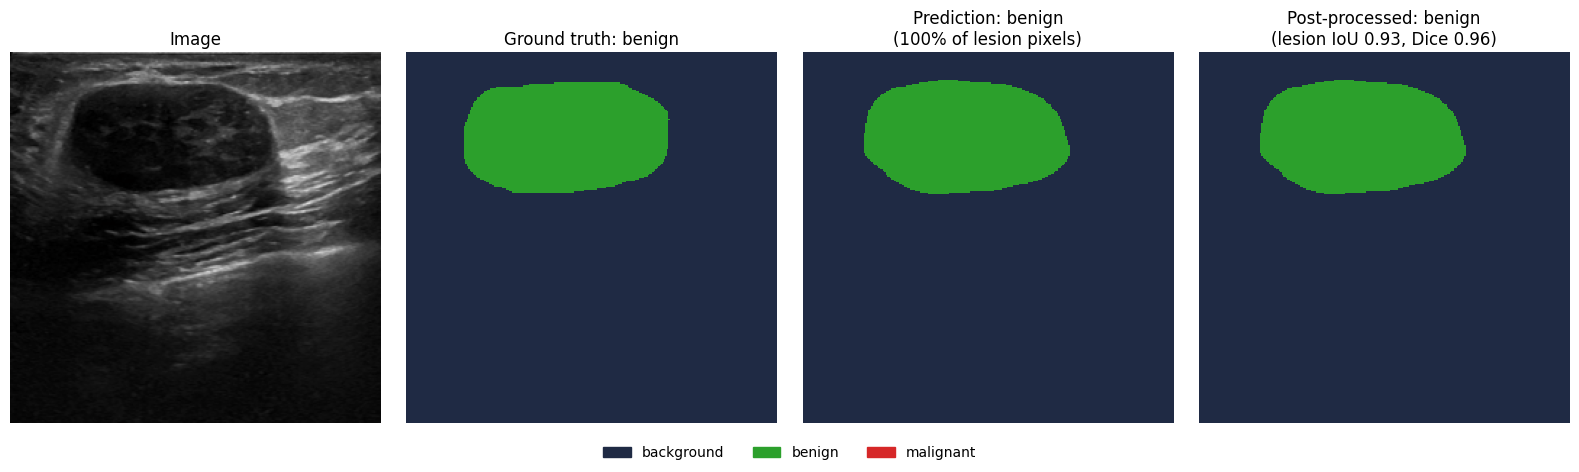

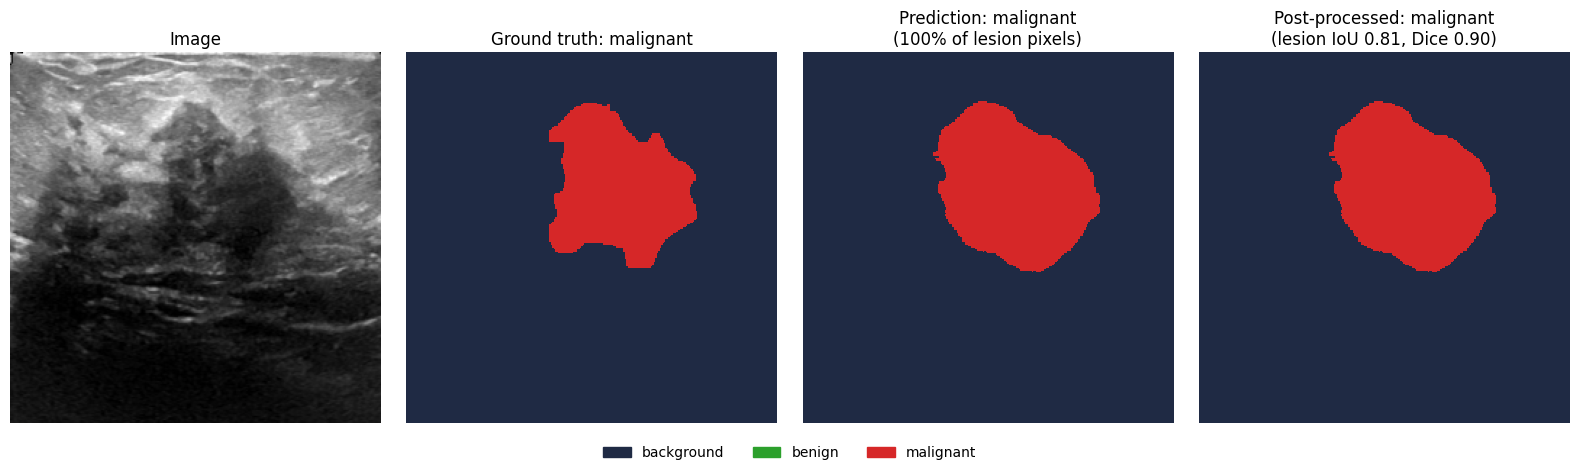

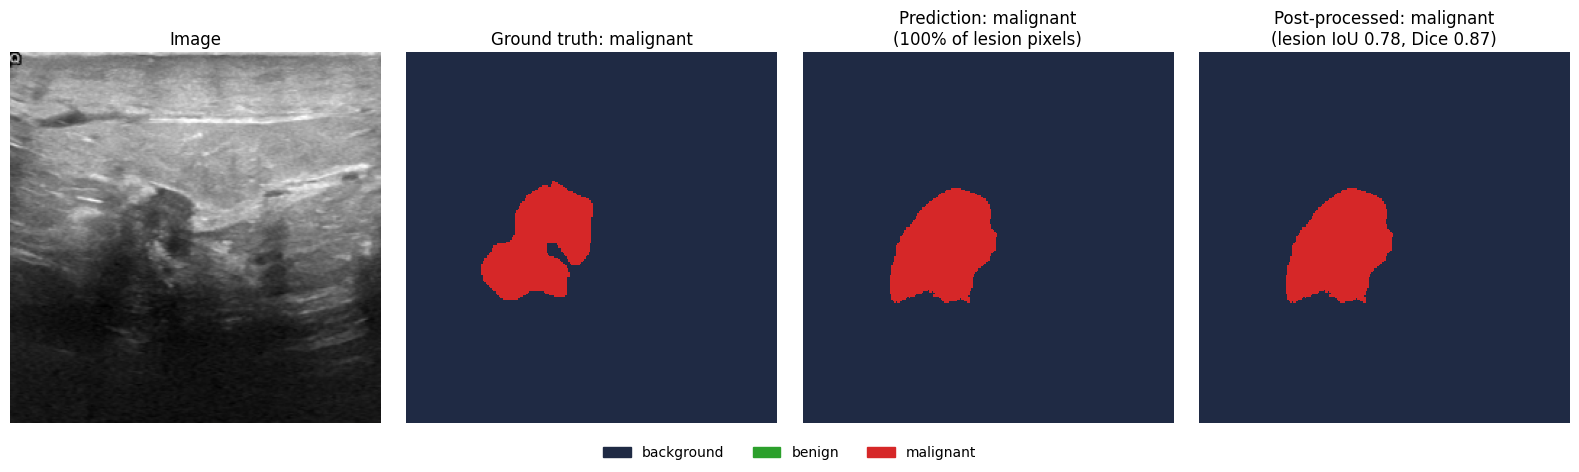

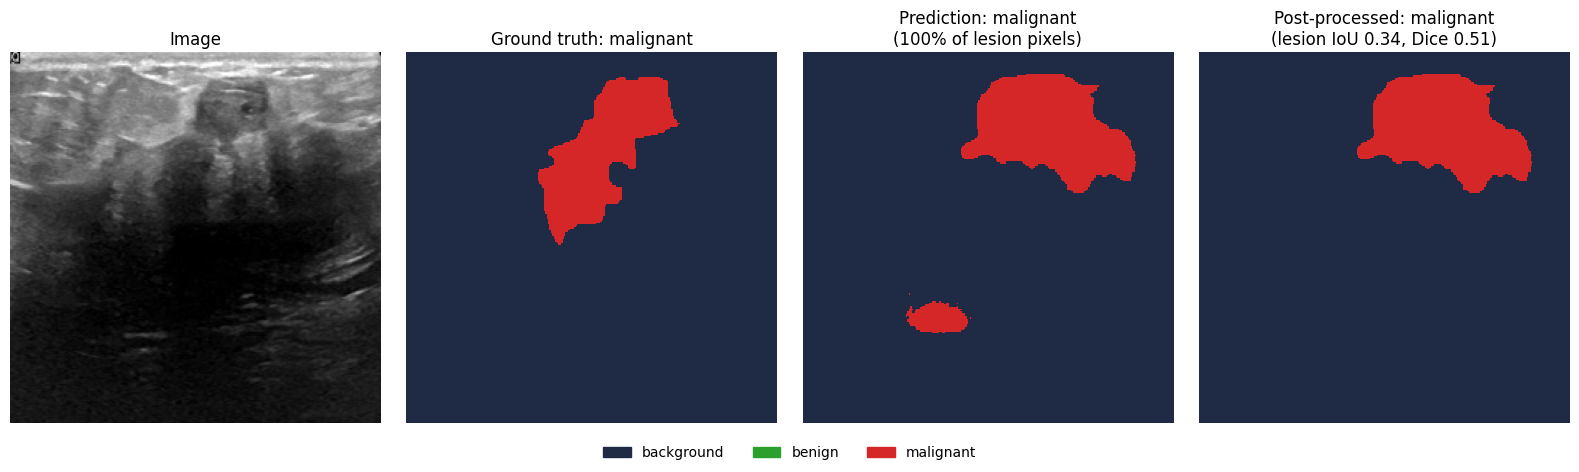

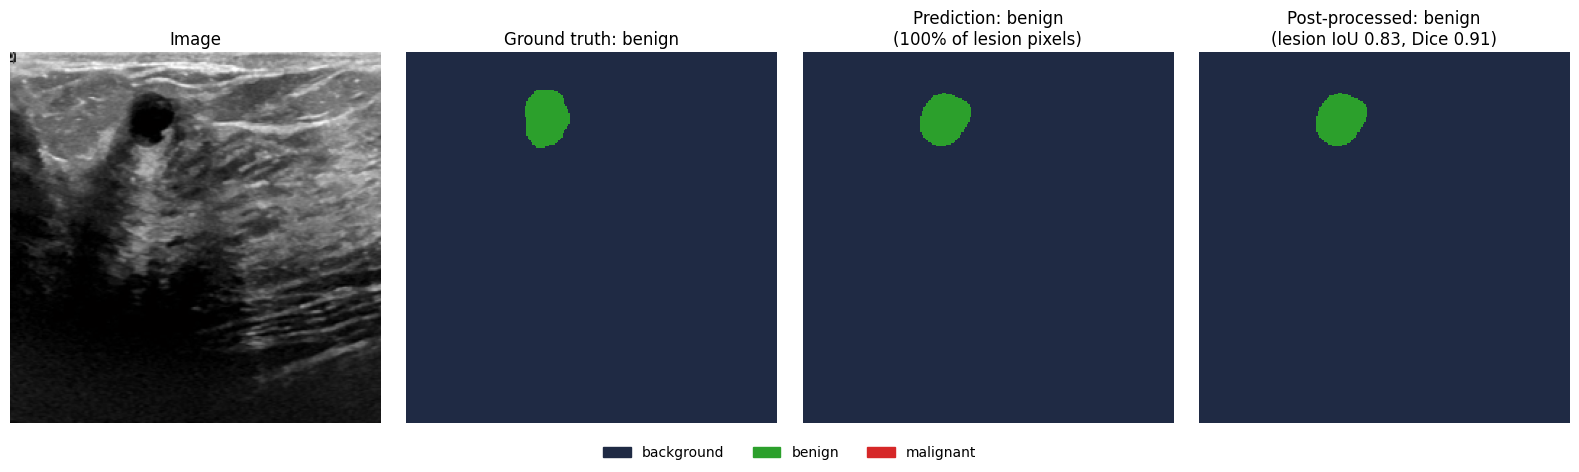

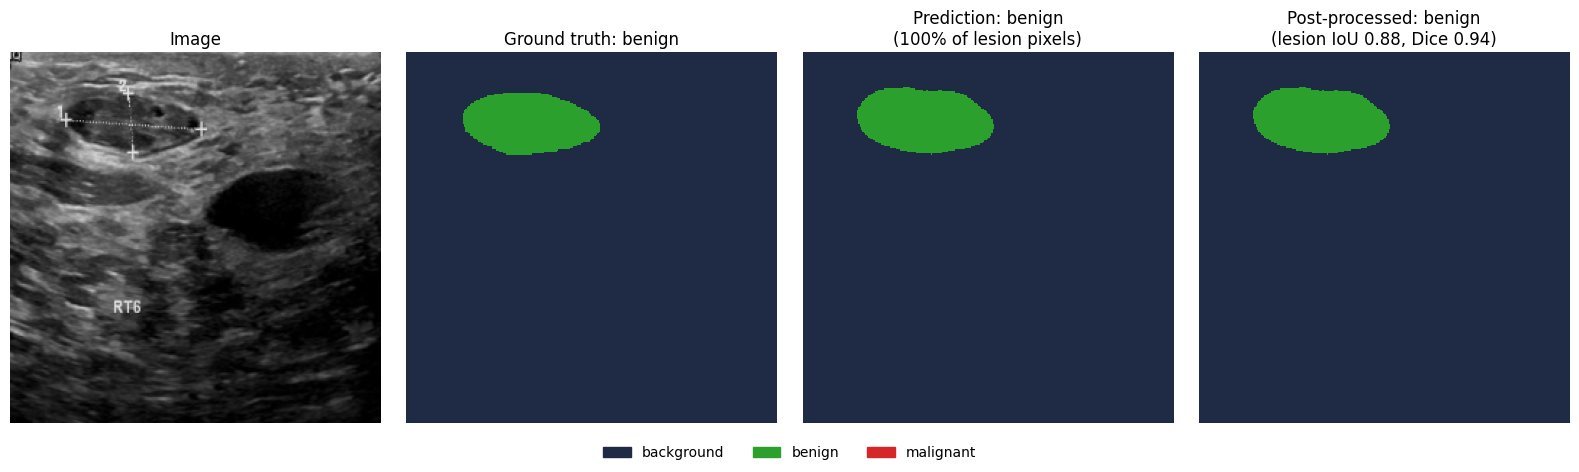

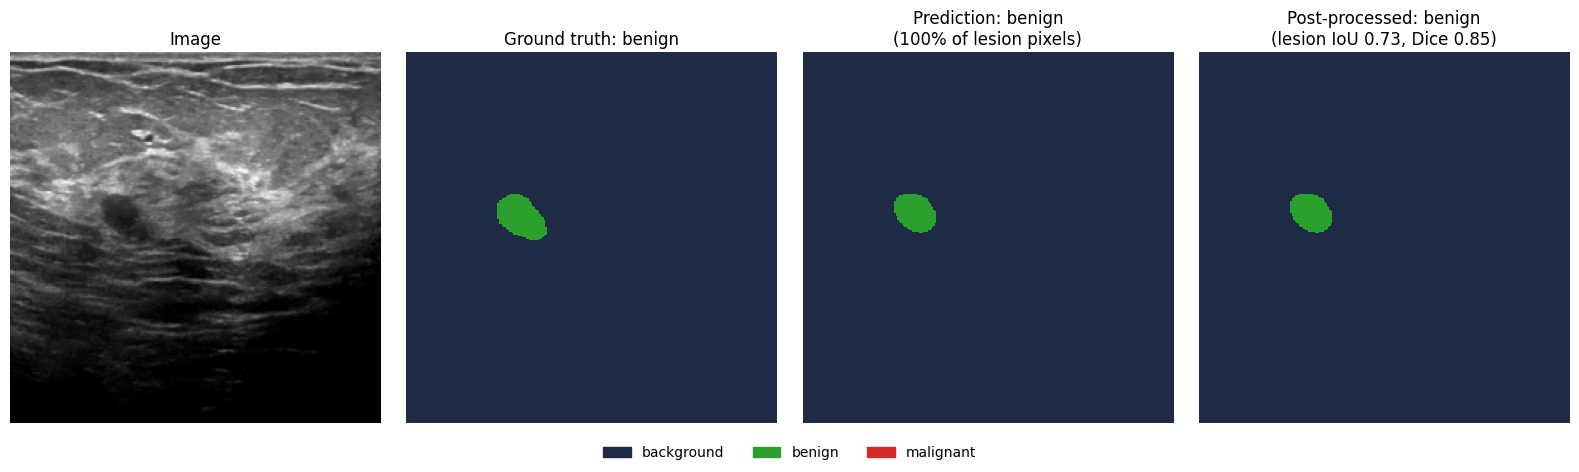

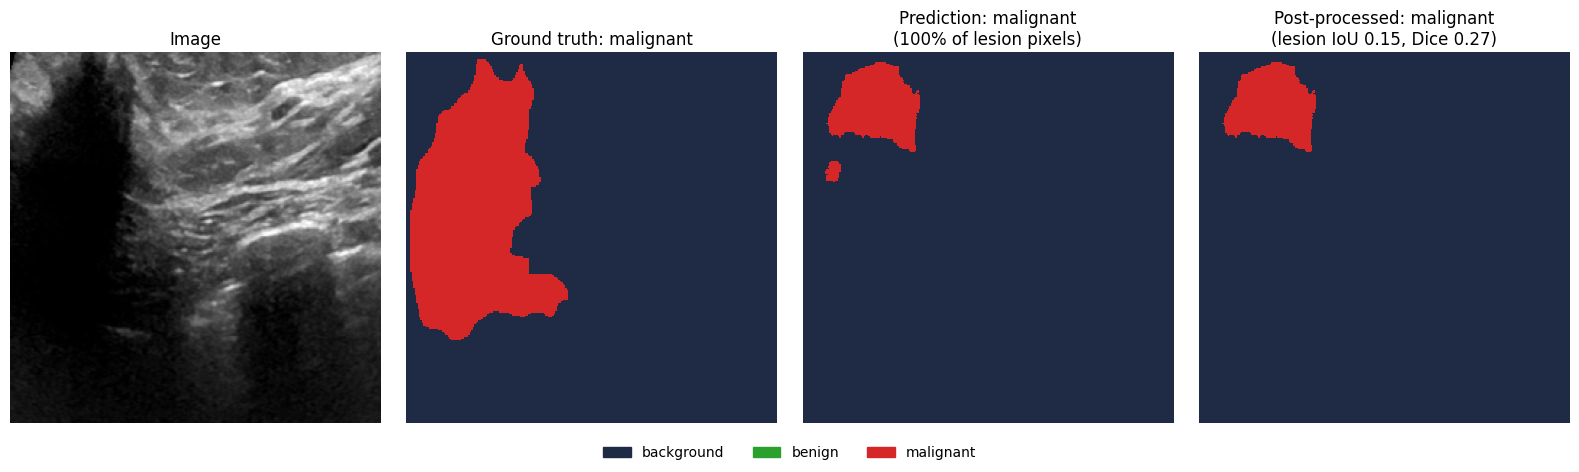

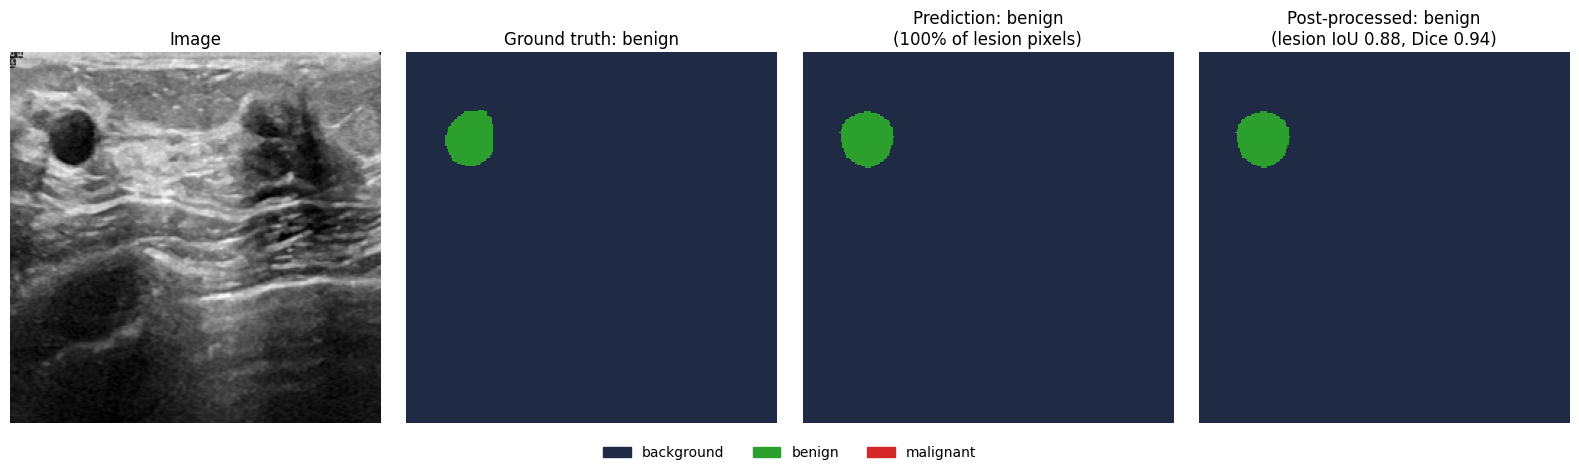

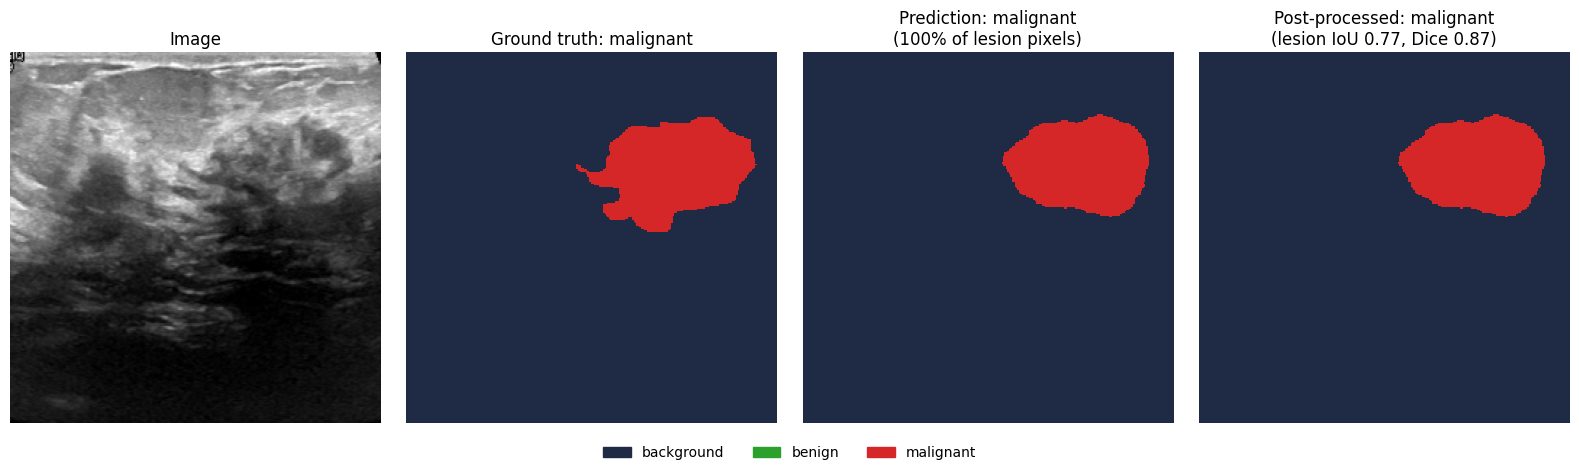

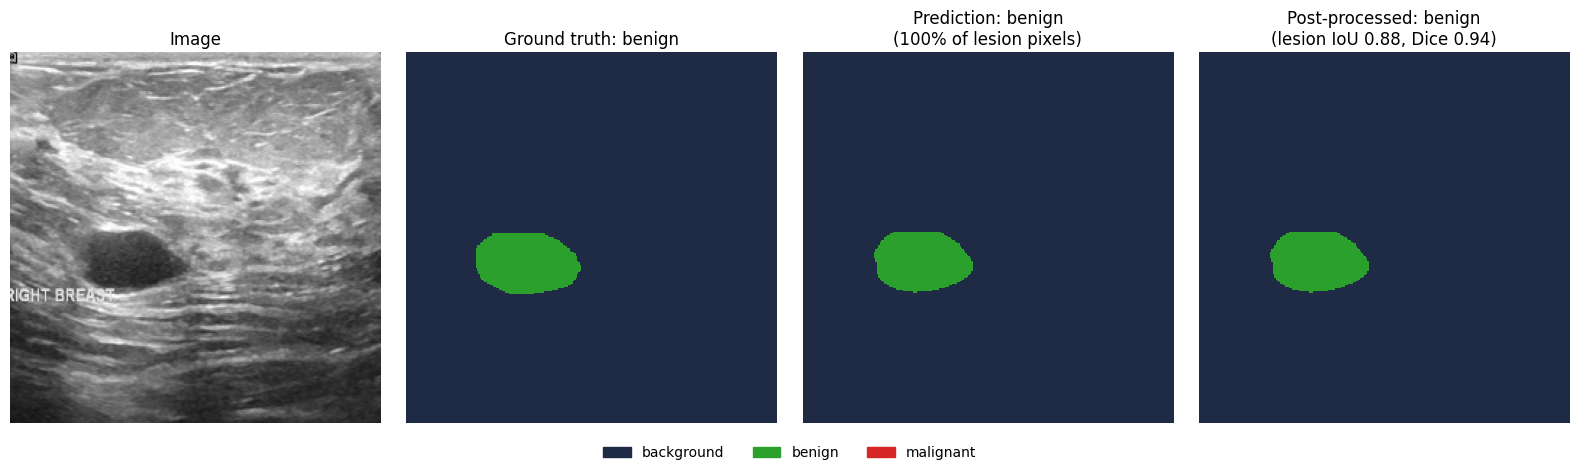

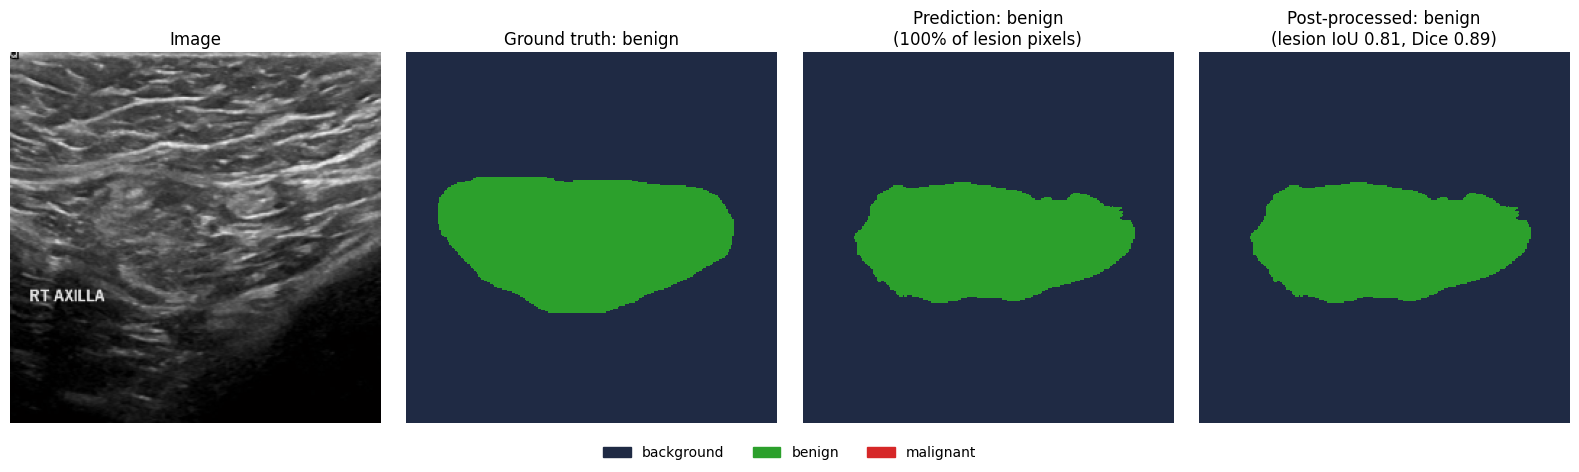

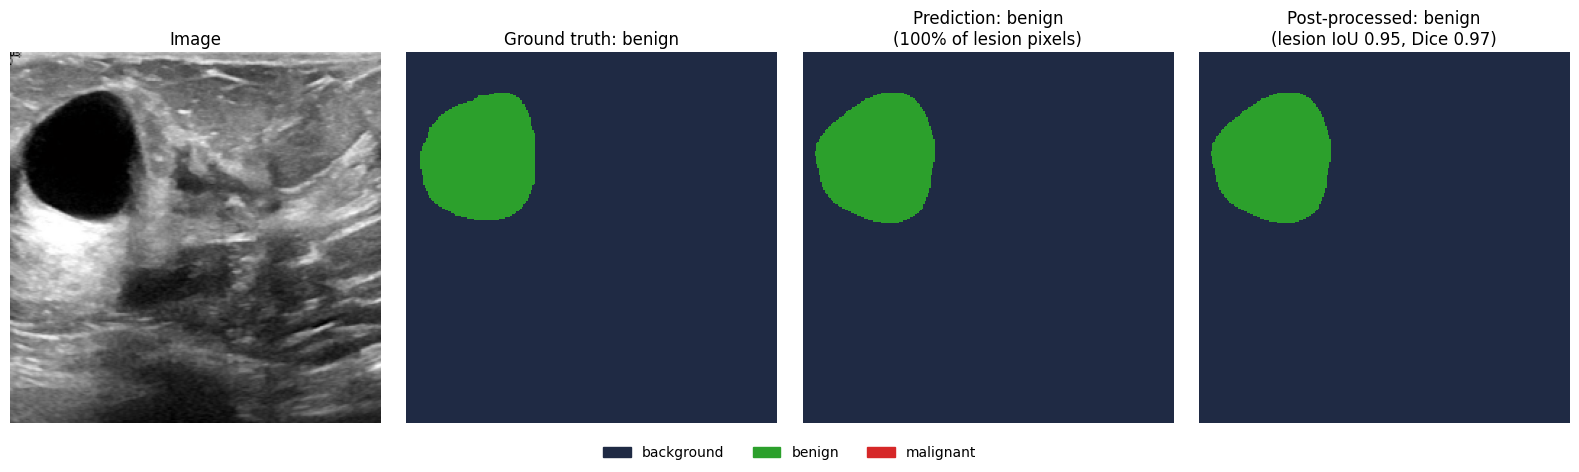

In [59]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# One fixed colour per class (0 = background, 1 = benign, 2 = malignant). vmin/vmax pin the
# mapping, so a colour means the same class in every panel; without them imshow rescales each
# mask to its own value range and colours change meaning between images.
CLASS_COLOURS = ["#1f2a44", "#2ca02c", "#d62728"]
mask_cmap = ListedColormap(CLASS_COLOURS)
legend = [Patch(color=colour, label=name) for colour, name in zip(CLASS_COLOURS, CLASS_NAMES)]


def call_title(pred):
    """The model's call for the image, with the share of lesion pixels behind it."""
    lesion = pred[pred > 0]
    if lesion.numel() == 0:
        return "no lesion found"
    call = lesion_call(pred)
    return f"{CLASS_NAMES[call]}\n({(lesion == call).float().mean().item():.0%} of lesion pixels)"


# The first batch of validation images and their predictions, from the metrics cell above.
# (Taking a batch with next(iter(val_loader)) instead would abandon a half-read pass over the
# loader, and its worker processes print "Bad file descriptor" errors as they shut down.)
for idx, image in enumerate(viz_images):
    true, pred, post = val_true[idx], val_pred[idx], val_post[idx]
    iou, dice = lesion_overlap(post, true)
    post_call = lesion_call(post)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))

    img = image.permute(1, 2, 0).numpy()
    if mean is not None and std is not None:
        img = img * std + mean  # Denormalize
    axes[0].imshow(np.clip(img, 0, 1))
    axes[0].set_title("Image")

    panels = [(true, f"Ground truth: {CLASS_NAMES[val_class[idx]]}"),
              (pred, f"Prediction: {call_title(pred)}"),
              (post, f"Post-processed: {CLASS_NAMES[post_call] if post_call else 'no lesion'}\n"
                     f"(lesion IoU {iou:.2f}, Dice {dice:.2f})")]
    for ax, (mask, title) in zip(axes[1:], panels):
        ax.imshow(mask.numpy(), cmap=mask_cmap, vmin=0, vmax=2, interpolation="nearest")
        ax.set_title(title)
    for ax in axes:
        ax.axis("off")

    fig.legend(handles=legend, loc="lower center", ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()
